# Diass – Centrale solaire publique

23 MW AC à Thiès

## 0. Setup

In [1]:
import os, sys
from pathlib import Path
# Trouver la racine du projet (contient src/deep_aero_sn)
ROOT = Path.cwd()
while not (ROOT / 'src' / 'deep_aero_sn').exists():
    if ROOT == ROOT.parent: break
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / 'src'))

import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates, torch
plt.style.use('seaborn-v0_8-darkgrid')
plt.rcParams['figure.figsize'] = (14, 5)
pd.set_option('display.max_columns', None)

from deep_aero_sn.config import config

## 1. Contexte du site

In [2]:
SITE = 'diass'
plant = config.require_plant('Diass')
plant

SolarPlantConfig(name='Diass', region='Thiès', location='Diass, département de Mbour, région de Thiès --- ~50 km au sud-est de Dakar', lat=14.65, lon=-17.1, commissioning='Mai 2022', sequence_length=None, forecast_horizon=None, power_dc_mwc=27.28, power_ac_mw=24.48, technology='polycristallin, structure fixe', mounting=<MountingType.FIXE: 'fixe'>, surface_tilt=15.0, surface_azimuth=0.0, n_modules=85248, module=PVModuleConfig(name='Jinko JKM320PP-72-V', cell_count=72, n_series=72, arrangement='6x12', p_max_wc=320.0, u_mpp_v=37.4, i_mpp_a=8.56, u_oc_v=46.4, i_sc_a=9.05, alpha_isc=0.06, beta_uoc=-144.0, gamma_pmax=-0.4, dimensions_mm=(1956.0, 992.0), mass_kg=26.5, efficiency_pct=16.49, max_system_voltage_v=1000.0, warranty_years=25, warranty_power_pct=80.0, stc_irradiance_wm2=1000, stc_temperature_c=25, technology='polycristallin', cell=PVCellConfig(name='Cellule Si multicristallin (Sénégal)', formats_mm=[(156, 156), (182, 182), (210, 210)], thickness_um_cristallin=(200, 300), thickness_u

### 1.1 Importation et préparation des données SCADA et météorologiques

Les données utilisées dans cette étude proviennent principalement des exports SCADA de la centrale de Diass, couvrant la période du 30 août 2025 au 31 août 2026. Les fichiers bruts, constitués de plusieurs classeurs Excel, ont été regroupés et transformés afin d'obtenir une structure temporelle homogène à une résolution de 15 minutes. Cette étape comprend notamment la normalisation des noms de variables, l'harmonisation des unités, le traitement des données nocturnes ainsi que l'agrégation des mesures issues des différents onduleurs afin de reconstituer les grandeurs à l'échelle de la centrale.

Les variables météorologiques absentes ou incomplètes dans les mesures SCADA ont été complétées à partir de données de réanalyse externes, principalement issues de NASA POWER et de MERRA-2, avec recours à ERA5 lorsque cela était nécessaire. Le principe retenu est de **privilégier systématiquement la mesure locale lorsqu'elle est disponible** et de n'utiliser la réanalyse qu'en complément. Cette approche permet d'éviter la multiplication de variables représentant une même grandeur physique et de conserver une traçabilité claire de leur origine.

Une attention particulière a également été portée à la qualité des données. Les valeurs manifestement aberrantes ont été identifiées à partir de contrôles de cohérence et de bornes physiques. Les valeurs manquantes de courte durée pour certaines variables météorologiques ont pu être interpolées, tandis que les variables électriques servant directement à définir la production, notamment la puissance active \(P_{ac}\), n'ont pas été artificiellement complétées. Les observations correspondantes sont ainsi exclues lors de la constitution des jeux d'apprentissage lorsque la variable cible est indisponible. Les données ayant fait l'objet d'une reconstruction sont par ailleurs identifiées par des indicateurs d'imputation afin d'en préserver la traçabilité.

Les variables de puissance extraites des fichiers SCADA étant exprimées en kW, elles sont converties en MW avant leur intégration au jeu de données final. Après ces différentes opérations, les données sont stockées au format Parquet dans le fichier `data/raw/diass/raw_input.parquet`, qui constitue la source d'entrée du pipeline de modélisation (chargée via `find_parquet`).

Une interruption de télémesure d'environ six jours, observée en décembre 2025, conduit à une absence réelle d'observations dans les données SCADA. Cette période n'a pas été reconstruite artificiellement afin de ne pas créer de pseudo-observations susceptibles d'altérer l'apprentissage des modèles. Elle est donc conservée comme une discontinuité du jeu de données et prise en compte lors de la constitution des échantillons d'apprentissage.


### Réanalyses externes

Les variables radiatives et météo non mesurées sur site (`ghi`, vent à 10 m,
point de rosée, HR, pression, précipitation, nébulosité) proviennent de la
**réanalyse NASA POWER (MERRA-2)** (source primaire documentée). Pour les 3 derniers
mois (juin-août 2026) que NASA n'a pas encore publié pour la composante solaire,
on comble avec l'**archive Open-Meteo (ERA5)** afin de produire un parquet complet.


### §1.2 Bloc électrique : du Data Leakage au Physics-Informed ML

La préparation spécifique à Diass est réalisée par `deep_aero_sn.data.diass.build_diass_raw` : lecture des exports SCADA, agrégation centrale, enrichissement météo, harmonisation à 15 minutes et création des variables électriques historiques. Le notebook conserve ici la justification scientifique et l'analyse des résultats ; les transformations utilisées par l'apprentissage vivent dans le package.

**Pourquoi les variables SCADA brutes sont interdites.** Utiliser les variables électriques SCADA **contemporaines** (`I_ac`, `P_dc`, `V_dc`, `V_dc_inv`, `I_dc`, `I_dc_inv`, `P_dc_inv`, `V_ac`, `cos_phi`, `energy_*_kwh`, `insolacion_kwh_m2`, `grid_frequency`) au même instant $t$ que la cible est un **data leakage**. Les mesures électriques contemporaines sont donc exclues du parquet final ; seules leurs transformations historiques, décalées de 24 heures, sont conservées.

Les variables historiques décrivent l'état passé de la centrale : rendement de conversion, soiling, stabilité électrique et état opérationnel. Elles peuvent ainsi compléter les variables météorologiques sans donner au modèle la réponse à prédire.

La règle appliquée est désormais centralisée : une absence de télémesure de `P_ac` reste une valeur manquante et n'est jamais transformée en pseudo-observation par le preprocessing.

In [3]:
from diass import build_diass_raw

DIASS_RAW = build_diass_raw(
    plant=plant,
    scada_dir="memory/Diass",
    output_path="data/raw/diass/raw_input.parquet",
    start="2025-08-30",
    end="2026-08-31",
)

print(f"Parquet brut Diass : {DIASS_RAW}")
print("La cible P_ac reste manquante lorsque la télémesure SCADA est absente.")

Parquet brut Diass : data\raw\diass\raw_input.parquet
La cible P_ac reste manquante lorsque la télémesure SCADA est absente.


In [4]:
# --- Activation "mode réel" : fenêtre + source pour la pipeline (§3+) ---
# Aligne la fenêtre d'entraînement sur le parquet réel, lu directement
# via find_parquet(plant, raw_dir) -> data/raw/diass/raw_input.parquet.
config.data.train_start = '2025-08-30'
config.data.train_end   = '2026-08-31'

print('Pipeline : fenêtre', config.data.train_start, '->', config.data.train_end,
      '; source = raw_input.parquet (SCADA réel diass)')

Pipeline : fenêtre 2025-08-30 -> 2026-08-31 ; source = raw_input.parquet (SCADA réel diass)


## 2. Exploration des données brutes

In [5]:
#df = pd.read_parquet(f'data/raw/{SITE}/raw_input.parquet')
df = pd.read_parquet(f'data/raw/{SITE}/raw_input.parquet')

df = df.drop(columns=[c for c in df.columns if c == 'is_imputed' or c.endswith('_is_imputed')])
print(f'{len(df)} lignes, {len(df.columns)} colonnes')
df.head(3)


35196 lignes, 55 colonnes


,T_inv,P_ac,G_sw,ghi,dni,dhi,cloud_cover,aod,dust,pm10,pm2_5,temp_air,temp_dew,relative_humidity,pressure,precipitation,wind_speed_2m,wind_speed_10m,wind_dir_2m,wind_dir_10m,wind_speed_station,wind_dir_station,wind_gust,density_air,albedo_sol,surface_tilt,surface_azimuth,clear_sky_ghi,V_dc_lag_24h,V_dc_inv_lag_24h,delta_V_dc_hist_24h,I_ac_lag_24h,I_dc_lag_24h,ratio_iac_idc_hist_24h,soiling_ratio_hist_24h,V_ac_lag_24h,V_ac_std_24h,cos_phi_lag_24h,grid_frequency_lag_24h,grid_freq_dev_hist_24h,P_dc_lag_24h,inverter_conv_hist_24h,inverter_conv_inv_hist_24h,inverter_efficiency_lag_24h,clipping_flag_lag_24h,is_operational_lag_24h,energy_ac_inc_lag_24h,energy_ac_sum_24h_hist,energy_dc_inc_lag_24h,energy_dc_sum_24h_hist,insolacion_lag_24h,insolacion_sum_24h_hist,pressure_abs_lag_24h,precip_local_lag_24h,precip_local_sum_24h_hist
2025-08-30 06:15:00,55.700000,-0.067250,0.000000,49.78,0.0,0.0,100.0,0.17,2.0,4.8,2.6,24.468667,24.437333,99.834000,1005.338333,0.0675,1.52,2.26,320.9,320.7,0.028667,30.521667,0.230000,1.163333,0.2,15.0,0.0,408.417511,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.97,0.97,0.97,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08-30 06:30:00,49.107143,-0.079537,0.000000,49.78,0.0,0.0,100.0,0.17,2.0,4.8,2.6,24.413000,24.406667,100.000000,1005.500000,0.0675,1.52,2.26,320.9,320.7,0.260000,79.706667,0.336667,1.163667,0.2,15.0,0.0,624.899383,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,0.97,0.97,0.97,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-08-30 06:45:00,37.989286,-0.081363,2.332333,49.78,0.0,0.0,100.0,0.17,2.0,4.8,2.6,24.469333,24.426667,99.798333,1005.578000,0.0675,1.52,2.26,320.9,320.7,0.317333,74.232667,0.402667,1.163000,0.2,15.0,0.0,794.918778,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,NaN,0.97,0.97,0.97,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
df.describe().round(2)

,T_inv,P_ac,G_sw,ghi,dni,dhi,cloud_cover,aod,dust,pm10,pm2_5,temp_air,temp_dew,relative_humidity,pressure,precipitation,wind_speed_2m,wind_speed_10m,wind_dir_2m,wind_dir_10m,wind_speed_station,wind_dir_station,wind_gust,density_air,albedo_sol,surface_tilt,surface_azimuth,clear_sky_ghi,V_dc_lag_24h,V_dc_inv_lag_24h,delta_V_dc_hist_24h,I_ac_lag_24h,I_dc_lag_24h,ratio_iac_idc_hist_24h,soiling_ratio_hist_24h,V_ac_lag_24h,V_ac_std_24h,cos_phi_lag_24h,grid_frequency_lag_24h,grid_freq_dev_hist_24h,P_dc_lag_24h,inverter_conv_hist_24h,inverter_conv_inv_hist_24h,inverter_efficiency_lag_24h,clipping_flag_lag_24h,is_operational_lag_24h,energy_ac_inc_lag_24h,energy_ac_sum_24h_hist,energy_dc_inc_lag_24h,energy_dc_sum_24h_hist,insolacion_lag_24h,insolacion_sum_24h_hist,pressure_abs_lag_24h,precip_local_lag_24h,precip_local_sum_24h_hist
count,34606.00,34602.00,34601.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,35196.00,34702.00,34702.00,34702.00,34583.00,35196.0,35196.0,35196.0,35196.00,34510.00,34510.00,34510.00,34506.00,34510.00,34506.00,35196.00,34506.00,34126.00,34506.00,34506.00,34506.00,34510.00,35196.00,35196.00,35196.00,35196.00,35196.00,34506.00,34126.00,34510.00,34320.00,34510.00,34320.00,34487.00,34487.00,33726.00
mean,44.24,3.90,248.77,241.95,223.31,82.80,53.96,0.31,102.77,88.48,29.01,25.71,18.63,70.05,1005.52,0.02,3.19,4.26,189.70,189.68,1.90,136.08,2.08,1.16,0.2,15.0,0.0,1230.95,343.00,338.22,4.77,76.90,183.24,1.00,1.28,31902.68,155.36,0.33,50.09,0.09,3.66,0.71,0.98,0.71,0.62,0.49,75.90,5414.87,54.78,5236.39,0.00,0.35,1005.42,0.02,1.22
std,6.85,5.38,338.42,320.13,284.28,100.25,41.96,0.15,89.65,66.41,19.75,4.75,6.68,22.79,1.91,0.06,1.40,1.78,132.68,132.69,1.05,119.22,1.26,0.02,0.0,0.0,0.0,307.16,311.46,312.06,32.62,99.02,249.55,0.50,0.56,533.39,504.97,0.62,0.68,0.24,4.95,0.23,0.09,0.23,0.49,0.50,3536.75,4100.81,144.41,2005.82,0.01,0.13,1.75,1.18,5.12
min,0.00,-0.14,0.00,0.00,0.00,0.00,0.00,0.04,0.00,4.40,2.60,14.16,-6.82,6.92,998.80,0.00,0.05,0.05,0.00,0.00,0.00,0.00,0.09,1.10,0.2,15.0,0.0,44.54,0.00,0.00,-146.03,0.00,0.59,0.50,0.00,0.00,65.48,-0.94,0.00,-5.00,-0.00,0.50,0.50,0.50,0.00,0.00,0.00,1235.00,0.00,1133.80,0.00,0.07,998.80,0.00,0.00
25%,39.26,-0.06,0.00,0.00,0.00,0.00,5.00,0.20,37.00,40.60,15.90,22.15,14.65,56.24,1004.30,0.00,2.03,2.84,39.80,39.70,1.11,38.75,1.23,1.15,0.2,15.0,0.0,1361.00,1.84,0.03,1.47,4.85,2.71,0.50,0.76,31837.61,93.38,-0.24,49.97,-0.03,0.00,0.50,1.00,0.50,0.00,0.00,0.00,3930.00,0.00,3723.80,0.00,0.25,1004.29,0.00,0.00
50%,44.91,-0.03,3.61,8.18,0.00,10.00,63.00,0.29,79.00,71.50,24.40,25.70,19.46,74.43,1005.50,0.00,3.22,4.28,237.60,237.50,1.91,83.60,2.07,1.16,0.2,15.0,0.0,1361.00,530.73,525.86,1.71,8.00,6.97,1.08,1.20,31912.17,101.00,-0.14,50.16,0.16,0.11,0.50,1.00,0.50,1.00,0.00,0.00,4587.00,0.00,4463.95,0.00,0.29,1005.47,0.00,0.00
75%,49.39,8.07,502.73,495.62,488.00,170.00,98.00,0.39,148.00,121.50,36.30,28.98,24.39,88.60,1006.68,0.01,4.24,5.56,316.70,316.60,2.58,280.65,2.81,1.18,0.2,15.0,0.0,1361.00,639.00,636.92,2.08,152.15,355.40,1.50,2.00,31987.69,109.10,0.96,50.26,0.26,7.45,1.00,1.00,1.00,1.00,1.00,5.00,6690.00,24.12,6418.99,0.00,0.43,1006.60,0.00,0.00
max,58.82,18.45,1200.75,1059.53,856.20,458.00,100.00,1.11,624.00,499.20,180.20,40.80,28.88,100.00,1014.40,2.48,7.54,9.98,359.90,359.90,40.00,358.94,40.00,1.22,0.2,15.0,0.0,1361.00,745.68,744.53,447.30,347.64,928.95,1.50,2.00,33113.11,6011.03,1.00,50.65,0.65,16.88,1.00,1.00,1.00,1.00,1.00,656272.00,660892.00,2392.77,13724.79,0.23,0.91,1011.09,215.61,215.61


### 2.1 Profil journalier

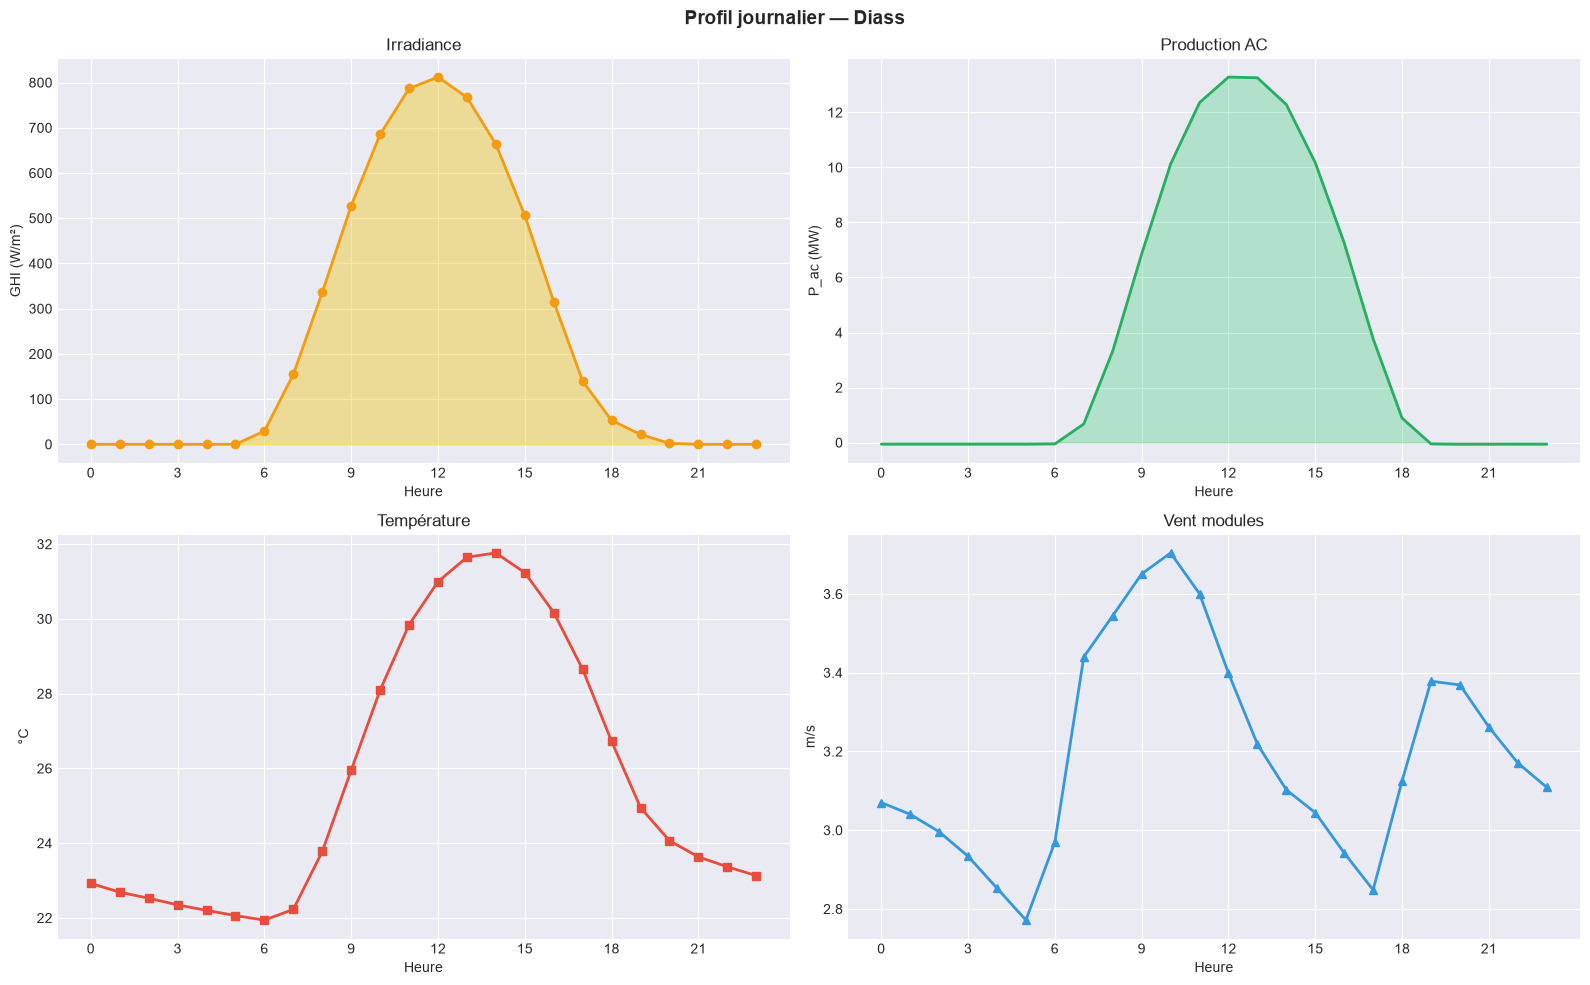

In [7]:
daily = df.groupby(df.index.to_series().dt.hour).mean(numeric_only=True)
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0,0].fill_between(daily.index, daily['ghi'], alpha=0.4, color='#f1c40f')
axes[0,0].plot(daily.index, daily['ghi'], 'o-', color='#f39c12', lw=2)
axes[0,0].set(title='Irradiance', ylabel='GHI (W/m\u00b2)')
axes[0,1].fill_between(daily.index, daily['P_ac'], alpha=0.3, color='#2ecc71')
axes[0,1].plot(daily.index, daily['P_ac'], color='#27ae60', lw=2)
axes[0,1].set(title='Production AC', ylabel='P_ac (MW)')
axes[1,0].plot(daily.index, daily['temp_air'], 's-', color='#e74c3c', lw=2)
axes[1,0].set(title='Température', ylabel='\u00b0C')
axes[1,1].plot(daily.index, daily['wind_speed_2m'], '^-', color='#3498db', lw=2)
axes[1,1].set(title='Vent modules', ylabel='m/s')
for ax in axes.flat: ax.set(xlabel='Heure', xticks=range(0,24,3))
plt.suptitle(f'Profil journalier — {plant.name}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.2 Série temporelle — 1 semaine

C:\Users\ROG ZEPHYRUS G14\AppData\Local\Temp\ipykernel_33732\3823675161.py:2: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  w = df.loc[WEEK:pd.Timestamp(WEEK)+pd.Timedelta(days=7)]


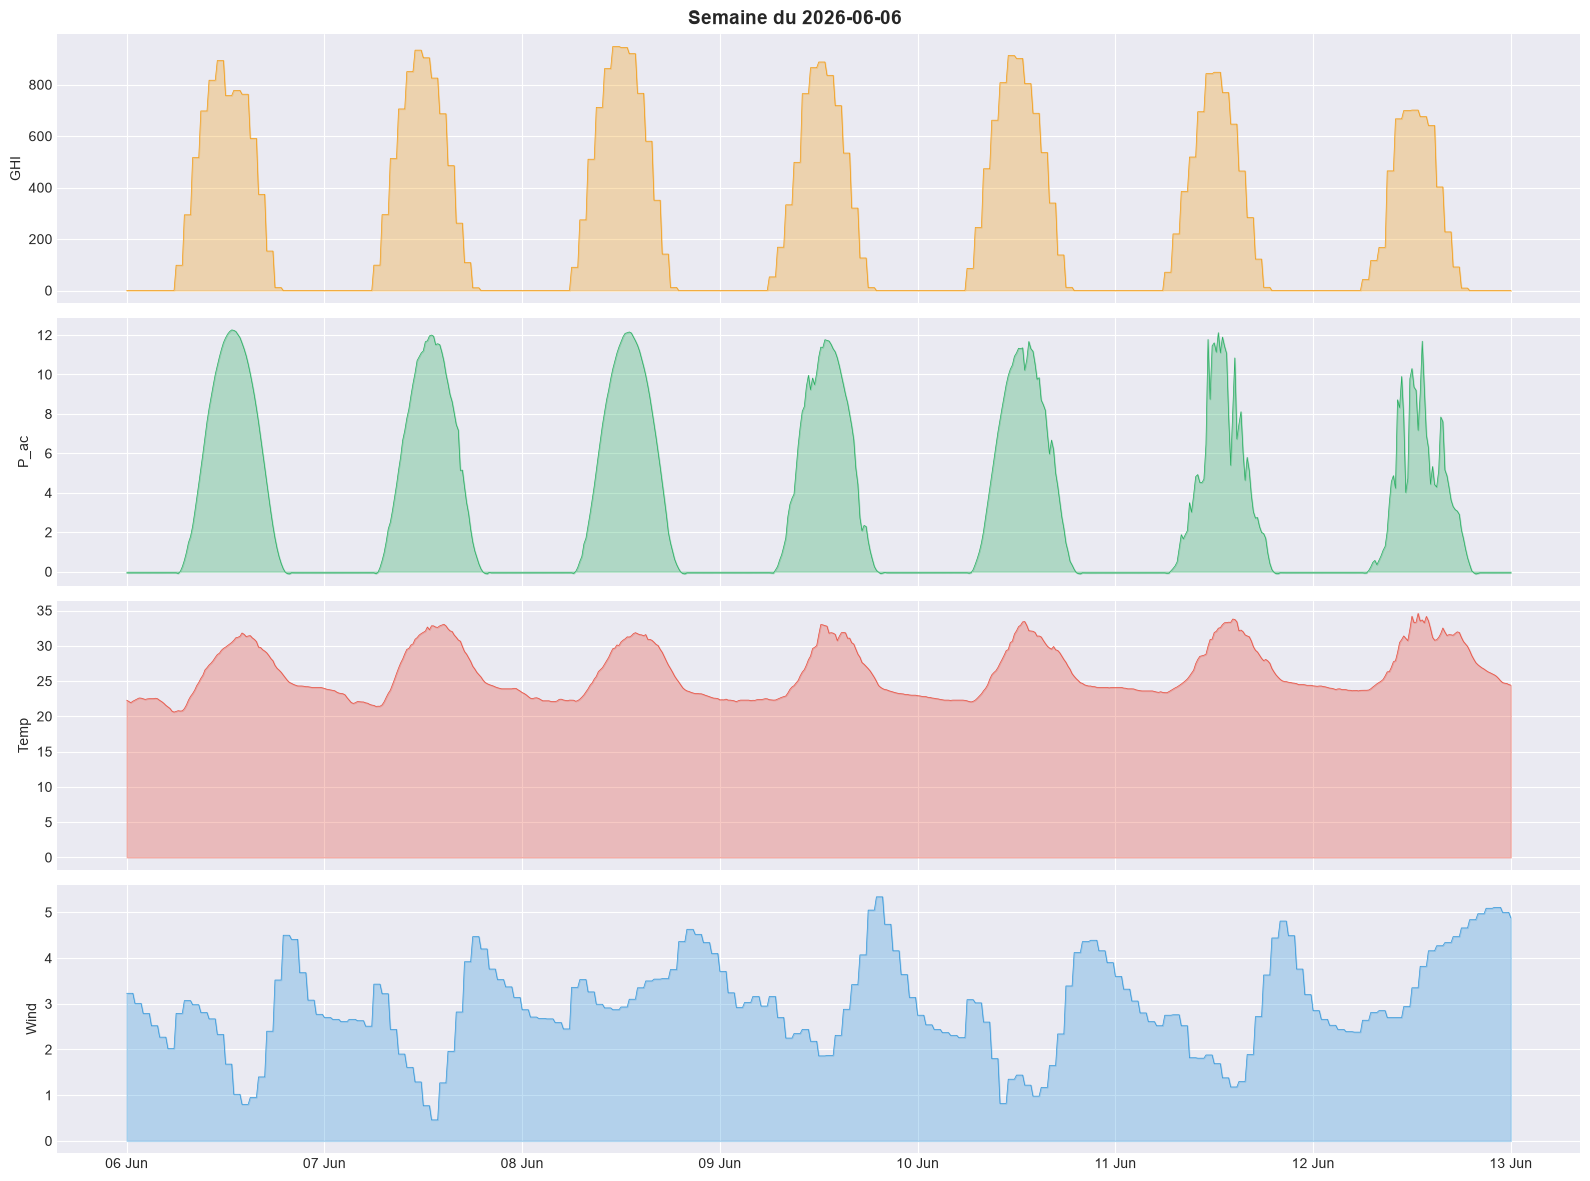

In [8]:
WEEK = '2026-06-06'
w = df.loc[WEEK:pd.Timestamp(WEEK)+pd.Timedelta(days=7)]
fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
for ax, col, c, lbl in zip(axes, ['ghi','P_ac','temp_air','wind_speed_2m'],
    ['#f39c12','#27ae60','#e74c3c','#3498db'], ['GHI','P_ac','Temp','Wind']):
    ax.fill_between(w.index, w[col], alpha=0.3, color=c)
    ax.plot(w.index, w[col], color=c, lw=0.5)
    ax.set_ylabel(lbl)
for ax in axes: ax.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
plt.suptitle(f'Semaine du {WEEK}', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.3 Corrélations

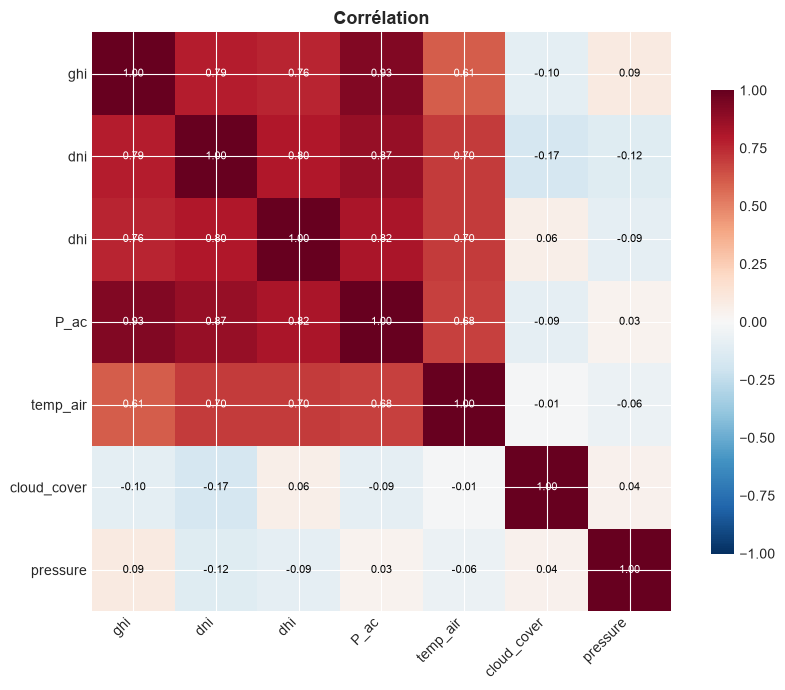

In [9]:
cols = [c for c in ['ghi','dni','dhi','P_ac','temp_air','cloud_cover','pressure'] if c in df.columns]
corr = df[cols].resample('1h').mean().dropna(how='all').corr()
corr_v = corr.to_numpy(dtype=float)
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr_v, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(cols))); ax.set_yticks(range(len(cols)))
ax.set_xticklabels(cols, rotation=45, ha='right'); ax.set_yticklabels(cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f'{corr_v[i, j]:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(corr_v[i, j]) > 0.5 else 'black')
plt.colorbar(im, ax=ax, shrink=0.8)
plt.title('Corrélation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.4 GHI vs Production

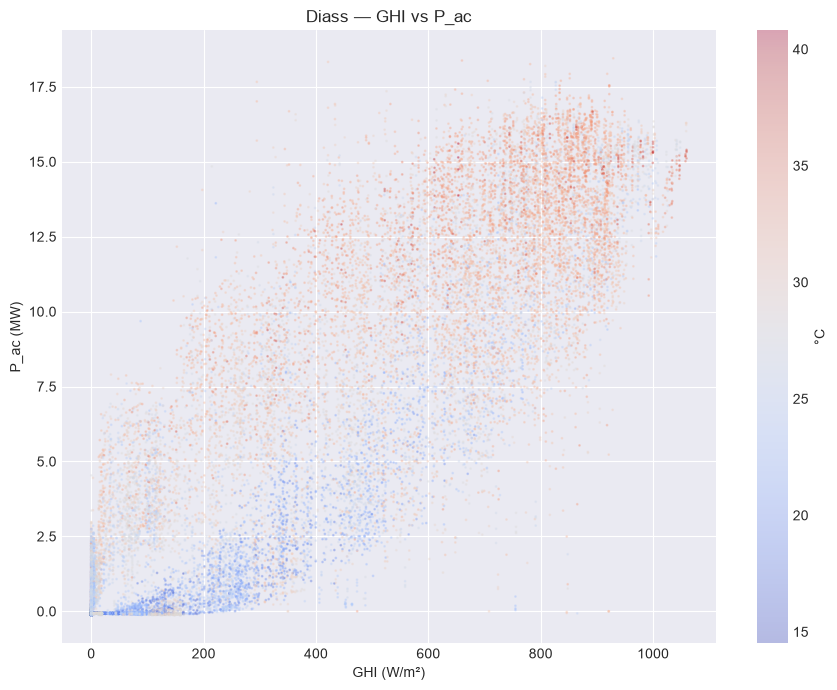

In [10]:
s = df.resample('10min').mean(numeric_only=True)[['ghi','P_ac','temp_air']].dropna()
fig, ax = plt.subplots(figsize=(9, 7))
sc = ax.scatter(s['ghi'], s['P_ac'], c=s['temp_air'], cmap='coolwarm', s=1, alpha=0.3)
plt.colorbar(sc, label='\u00b0C')
ax.set(xlabel='GHI (W/m\u00b2)', ylabel='P_ac (MW)', title=f'{plant.name} — GHI vs P_ac')
plt.tight_layout()
plt.show()

## 2.5 Physique du site solaire

### 2.5.1 Indice clear-sky

L'indice ciel clair mesure la fraction du rayonnement qui traverse l'atmosph\`ere. $\xi_{cc} = 1$ = ciel d\`egage ; $\xi_{cc} < 1$ = nuages / a\'erosols. Formule : $\xi_{cc} = GHI_{obs} / GHI_{clear}$ (Ineichen).

In [11]:
df_daily = df.resample('1h').mean(numeric_only=True).dropna(how='all')

# Indice clear-sky : albedo_ciel_clair est le GHI ciel clair (Ineichen)
if 'albedo_ciel_clair' in df_daily.columns:
    df_daily['clearsky_index'] = df_daily['ghi'] / df_daily['albedo_ciel_clair'].replace(0, float('nan'))
    df_daily['clearsky_index'] = df_daily['clearsky_index'].clip(0, 1.5)

    fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    axes[0].plot(df_daily.index, df_daily['ghi'], label='GHI observ\u00e9', color='#f39c12', lw=1)
    axes[0].plot(df_daily.index, df_daily['albedo_ciel_clair'], label='GHI ciel clair',
                 color='#e74c3c', lw=1, alpha=0.7)
    axes[0].set(ylabel='W/m\u00b2', title='Irradiance observ\u00e9e vs ciel clair')
    axes[0].legend()

    axes[1].fill_between(df_daily.index, df_daily['clearsky_index'], alpha=0.4, color='#3498db')
    axes[1].axhline(y=1.0, color='red', ls='--', lw=1, label='$\\xi_{cc}=1$')
    axes[1].set(xlabel='Date', ylabel='$\\xi_{cc}$',
                title='Indice ciel clair — fraction de rayonnement transmise')
    axes[1].legend()
    _t0 = pd.Timestamp(config.data.train_start) if config.data.train_start else df_daily.index.min()
    _t1 = pd.Timestamp(config.data.train_end) if config.data.train_end else df_daily.index.max()
    axes[0].set_xlim(_t0, _t1)
    plt.tight_layout()
    plt.show()

    # Distribution
    fig, ax = plt.subplots(figsize=(10, 5))
    valid = df_daily['clearsky_index'].dropna()
    ax.hist(valid, bins=50, color='#3498db', alpha=0.7, edgecolor='white')
    ax.axvline(x=valid.mean(), color='red', ls='--', lw=2, label=f'Moyenne={valid.mean():.3f}')
    ax.set(xlabel='$\\xi_{cc}$', ylabel='Fr\u00e9quence',
           title='Distribution de l\u2019indice ciel clair')
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print('Colonne albedo_ciel_clair non disponible')

Colonne albedo_ciel_clair non disponible


### 2.5.2 Temperature de cellule (modele NOCT)

Le modele NOCT estime la temperature des cellules : $T_{cell} = T_{amb} + (NOCT - 20) / 800 \times G$ o\u00f9 $NOCT \approx 45°C$. Le coefficient thermique $\gamma \approx -0.43\%/°C$ reduit la puissance.

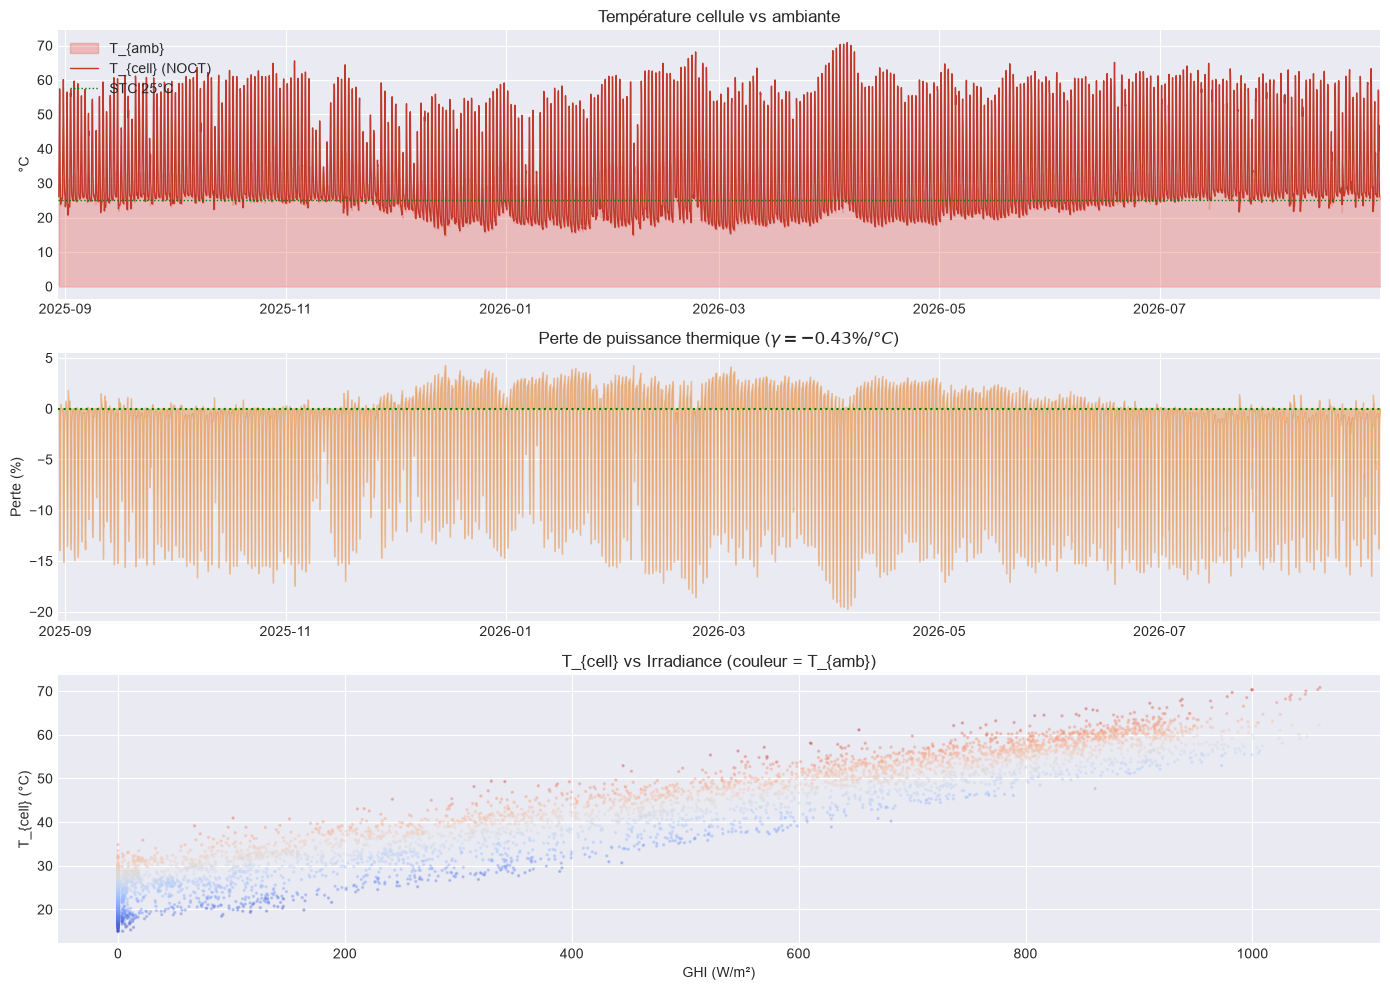

T cellule moyenne : 33.3°C
Perte thermique moyenne : -3.56%
Max T cellule : 70.8°C


In [12]:
NOCT = 45  # Nominal Operating Cell Temperature (°C)
G_ref = 800  # W/m² (conditions NOCT)
gamma = -0.0043  # -0.43%/°C coefficient thermique de puissance

df_physics = df.dropna(axis=0, how='all').resample('1h').mean(numeric_only=True).dropna(subset=['temp_air', 'ghi']).copy()
df_physics['T_cell'] = df_physics['temp_air'] + (NOCT - 20) / G_ref * df_physics['ghi']
df_physics['T_cell'] = df_physics['T_cell'].clip(15, 90)

# Perte thermique par rapport aux STC (25°C)
df_physics['thermal_loss_pct'] = (df_physics['T_cell'] - 25) * gamma * 100

fig, axes = plt.subplots(3, 1, figsize=(14, 10))
axes[0].fill_between(df_physics.index, df_physics['temp_air'], alpha=0.3, color='#e74c3c', label='T_{amb}')
axes[0].plot(df_physics.index, df_physics['T_cell'], color='#c0392b', lw=1, label='T_{cell} (NOCT)')
axes[0].axhline(y=25, color='green', ls=':', lw=1, label='STC 25°C')
axes[0].set(ylabel='°C', title='Temp\u00e9rature cellule vs ambiante')
axes[0].legend()

axes[1].fill_between(df_physics.index, df_physics['thermal_loss_pct'], alpha=0.4, color='#e67e22')
axes[1].axhline(y=0, color='green', ls=':')
axes[1].set(ylabel='Perte (%)', title='Perte de puissance thermique ($\\gamma = -0.43\\%/°C$)')

axes[2].scatter(df_physics['ghi'], df_physics['T_cell'], c=df_physics['temp_air'],
                cmap='coolwarm', s=2, alpha=0.3)
axes[2].set(xlabel='GHI (W/m²)', ylabel='T_{cell} (°C)',
             title='T_{cell} vs Irradiance (couleur = T_{amb})')

_t0 = pd.Timestamp(config.data.train_start) if config.data.train_start else df_physics.index.min()
_t1 = pd.Timestamp(config.data.train_end) if config.data.train_end else df_physics.index.max()
axes[0].set_xlim(_t0, _t1)
axes[1].set_xlim(_t0, _t1)

plt.tight_layout()
plt.show()

print(f'T cellule moyenne : {df_physics["T_cell"].mean():.1f}°C')
print(f'Perte thermique moyenne : {df_physics["thermal_loss_pct"].mean():.2f}%')
print(f'Max T cellule : {df_physics["T_cell"].max():.1f}°C')

### 2.5.3 Effet de la couverture nuageuse sur la variabilit\u00e9 du GHI

La couverture nuageuse ($c_{cov}$) est la premi\`ere source de variabilit\u00e9 intrajournali\`ere. Sous ciel clair, $c_{cov} \approx 0$ et la courbe GHI est lisse ; sous ciel nuageux, la variabilit\u00e9 augmente (passages de cumulus).

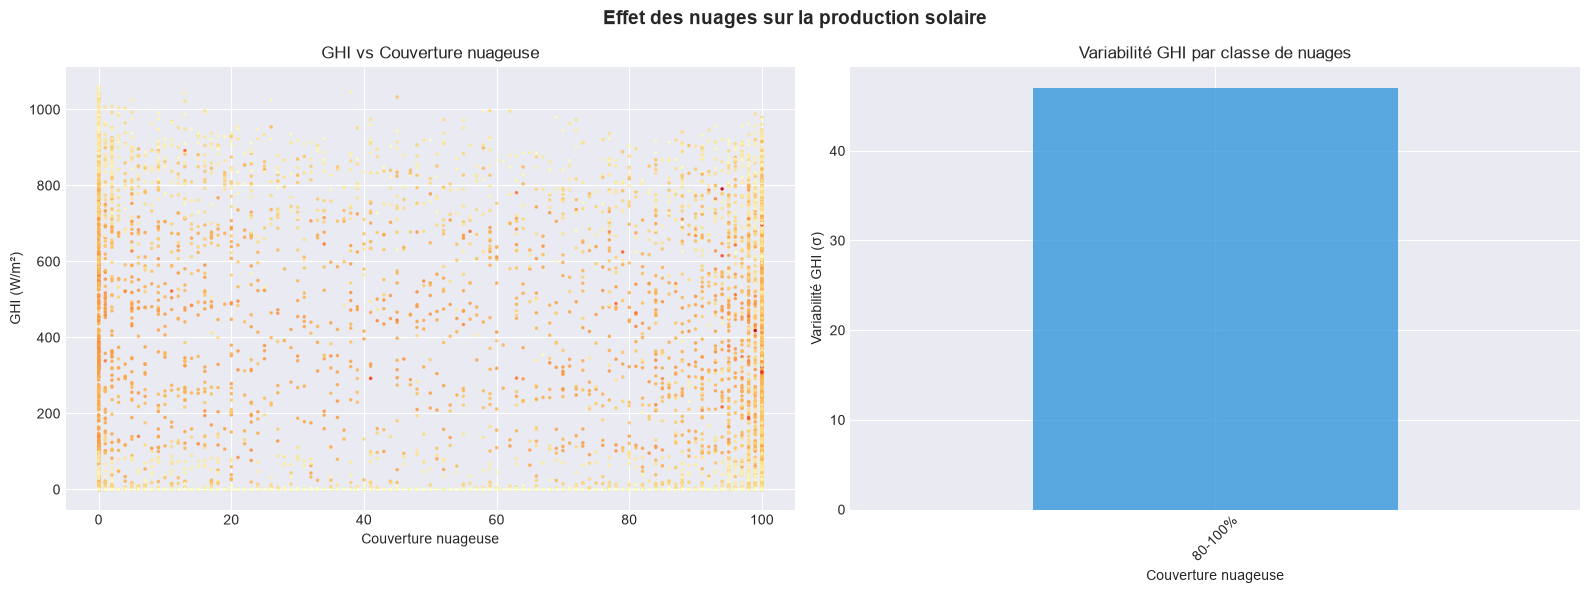

In [13]:
df_cloud = df.resample('10min').mean(numeric_only=True)[['ghi', 'cloud_cover']].dropna()
df_cloud['ghi_var'] = df_cloud['ghi'].rolling(6).std()  # Variabilit\u00e9 sur 1h
df_cloud = df_cloud.dropna()

# Bins de couverture nuageuse
bins = [0, 0.2, 0.4, 0.6, 0.8, 1.0]
labels = ['0-20%', '20-40%', '40-60%', '60-80%', '80-100%']
df_cloud['cloud_bin'] = pd.cut(df_cloud['cloud_cover'], bins=bins, labels=labels)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scatter
axes[0].scatter(df_cloud['cloud_cover'], df_cloud['ghi'], c=df_cloud['ghi_var'],
                cmap='YlOrRd', s=2, alpha=0.3)
axes[0].set(xlabel='Couverture nuageuse', ylabel='GHI (W/m²)',
             title='GHI vs Couverture nuageuse')

# Variabilit\u00e9 par bin
if df_cloud['cloud_bin'].notna().any():
    variability_by_cloud = df_cloud.groupby('cloud_bin', observed=True)['ghi_var'].mean()
    variability_by_cloud.plot(kind='bar', ax=axes[1], color='#3498db', alpha=0.8)
    axes[1].set(xlabel='Couverture nuageuse', ylabel='Variabilit\u00e9 GHI (σ)',
                title='Variabilit\u00e9 GHI par classe de nuages')
    axes[1].tick_params(axis='x', rotation=45)

plt.suptitle('Effet des nuages sur la production solaire', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 2.5.4 Effet des aerosols (AOD) sur l'irradiance

L'AOD ($\tau_a$) mesure l'epaisseur optique des aerosols. Pendant l'harmattan, $\tau_a$ augmente et reduit l'irradiance GHI.

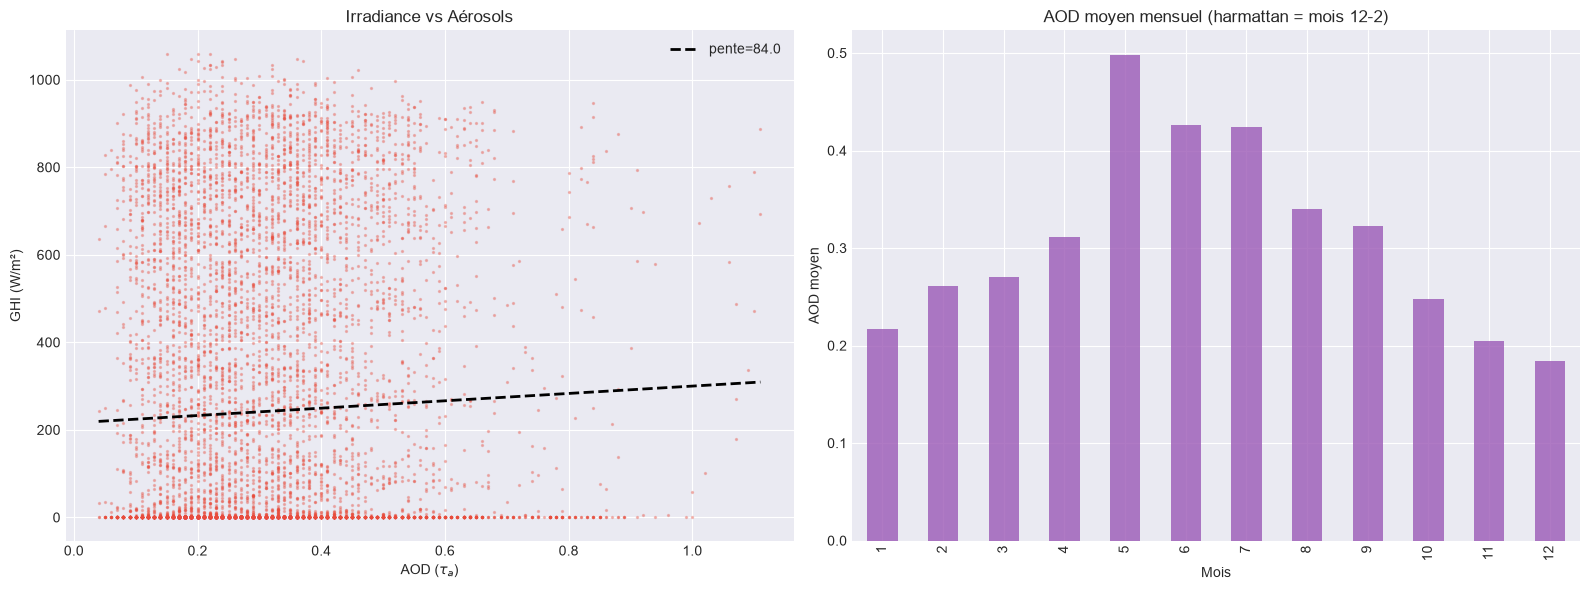

In [14]:
df_aod = df.resample('1h').mean(numeric_only=True).dropna(how='all')[['ghi', 'aod']].dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].scatter(df_aod['aod'], df_aod['ghi'], s=2, alpha=0.3, color='#e74c3c')
# Tendance
if len(df_aod) > 10:
    z = np.polyfit(df_aod['aod'].dropna(), df_aod.loc[df_aod['aod'].notna(), 'ghi'], 1)
    x_line = np.linspace(df_aod['aod'].min(), df_aod['aod'].max(), 100)
    axes[0].plot(x_line, np.polyval(z, x_line), 'k--', lw=2, label=f'pente={z[0]:.1f}')
    axes[0].legend()
axes[0].set(xlabel='AOD ($\\tau_a$)', ylabel='GHI (W/m²)',
             title='Irradiance vs Aérosols')

# AOD mensuel
df_aod['month'] = pd.to_datetime(df_aod.index).month
aod_monthly = df_aod.groupby('month')['aod'].mean()
aod_monthly.plot(kind='bar', ax=axes[1], color='#9b59b6', alpha=0.8)
axes[1].set(xlabel='Mois', ylabel='AOD moyen',
         title='AOD moyen mensuel (harmattan = mois 12-2)')
plt.tight_layout()
plt.show()

### 2.5.5 influence des periodes de pluie sur la production solaire


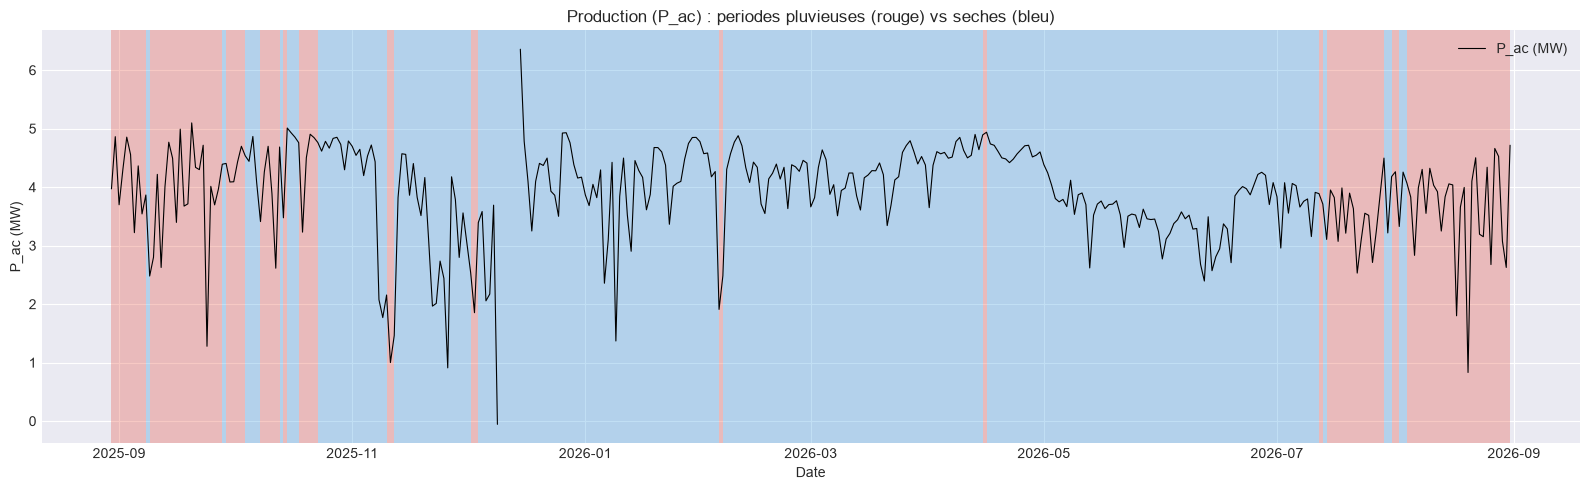

Jours pluvieux (> 1 mm) : 96 | secs : 271
P_ac moyen (MW) : pluie 3.7 vs sec 4.0 (-6%)


In [15]:
# --- Influence de la pluie sur la production : courbe P_ac coloree par pluie/sec ---
# Jour pluvieux : cumul quotidien de precipitation > 1 mm.
df['is_raining'] = (df['precipitation'] > 0.1).astype(float)

_day = df.resample('1D').agg({'precipitation': 'sum', 'P_ac': 'mean'})
_day['rainy'] = _day['precipitation'] > 1.0

fig, ax = plt.subplots(figsize=(16, 5))

# Colorer l'arriere-plan : rouge = pluvieux, bleu = sec
for i_day in range(len(_day) - 1):
    color = '#e74c3c' if _day['rainy'].iloc[i_day] else '#3498db'
    ax.axvspan(_day.index[i_day], _day.index[i_day + 1], alpha=0.3, color=color, linewidth=0)

ax.plot(_day.index, _day['P_ac'], color='black', linewidth=0.8, label='P_ac (MW)')
ax.set(ylabel='P_ac (MW)', xlabel='Date',
       title='Production (P_ac) : periodes pluvieuses (rouge) vs seches (bleu)')
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

_rain, _dry = _day[_day['rainy']], _day[~_day['rainy']]
print(f'Jours pluvieux (> 1 mm) : {len(_rain)} | secs : {len(_dry)}')
_p_r, _p_d = _rain['P_ac'].mean(), _dry['P_ac'].mean()
print(f'P_ac moyen (MW) : pluie {_p_r:.1f} vs sec {_p_d:.1f} '
      f'({(_p_r / _p_d - 1) * 100:+.0f}%)')

## 3. Feature engineering

In [16]:
from deep_aero_sn.pipelines.data.data_pipeline import data_pipeline

# La sélection avancée reste activée ici uniquement pour l'analyse comparative.
result = data_pipeline(plant, select_features=True)
print(f"Features stockees : {result['n_features']} colonnes | {result['feature_path']}")
print(f"Selection : {result.get('n_features_selected')} / {result.get('n_features_input')} "
      f"features retenues (union de {len(result.get('selection_results', {}))} methodes)")

2026-10-06 18:09:54 | deep_aero_sn | INFO | Modele local charge : tcn__diass (tcn, dim=425)


18:09:54.724 | INFO    | deep_aero_sn - Modele local charge : tcn__diass (tcn, dim=425)

2026-10-06 18:09:54 | deep_aero_sn | INFO | Modele local charge : lstm_baseline__diass (lstm_baseline, dim=425)


18:09:54.844 | INFO    | deep_aero_sn - Modele local charge : lstm_baseline__diass (lstm_baseline, dim=425)

2026-10-06 18:09:55 | deep_aero_sn | INFO | Modele local charge : mlp__diass (mlp, dim=425)


18:09:55.098 | INFO    | deep_aero_sn - Modele local charge : mlp__diass (mlp, dim=425)

... (83 outputs left out)

2026-10-06 18:11:29 | deep_aero_sn | INFO | Selection : 424 / 543 features retenues pour Diass


18:11:29.241 | INFO    | deep_aero_sn - Selection : 424 / 543 features retenues pour Diass

18:11:30.000 | INFO    | Flow run 'maize-snake' - Finished in state Completed()

Features stockees : 427 colonnes | data\features\diass_features.parquet
Selection : 424 / 543 features retenues (union de 7 methodes)


## 3.2 Selection de features (FeatureSelector)

Le `FeatureEngineeringPipeline` embarque `self.selector = FeatureSelector()` : toutes
les methodes (`correlation`, `mutual_info`, `pca`, `rfe`, `vif`, `permutation`, `shap`)
sont appliquees en serie, puis la selection finale est l'**union** des features retenues
par chaque methode. Les resultats (`selection_results`, `selected_features`,
`selection_importances`) sont exposes ci-dessous.

Chaque methode expose un diagnostic de nature differente (`score` de correlation,
information mutuelle, `rank` de RFE, `vif`, importances permutation/SHAP, variance
expliquee pour la PCA). Le bloc suivant les **normalise** (rangs et VIF inverses,
correlation en |r|) pour les comparer sur une meme echelle, sans relancer aucun
selecteur, puis detaille : volume retenu, top-12 par methode, variance de la PCA,
recouvrement entre methodes (Jaccard), consensus et repartition par famille de
variables.

In [17]:
# --- Selection : recuperation des resultats du flux (aucun recalcul) ---
# data_pipeline(select_features=True) a deja execute le FeatureSelector (union des
# methodes) et le parquet ne contient plus que les features retenues. On retrouve
# ici les metadonnees pour l'analyse et les graphes.

sel_results = result.get('selection_results', {})
sel_union = result.get('selected_features', [])
n_features_in = int(result.get('n_features_input') or 0)
n_features_sel = int(result.get('n_features_selected') or 0)
sel_importances = result.get('selection_importances')

print(f"Selection (data_pipeline) : {n_features_sel} / {n_features_in} features retenues (cible exclue)")
print(f"Methodes appliquees : {', '.join(sel_results.keys())}")
print(f"Extrait de l'union : {sel_union[:6]} ...")

Selection (data_pipeline) : 424 / 543 features retenues (cible exclue)
Methodes appliquees : correlation, mutual_info, pca, rfe, vif, permutation, shap
Extrait de l'union : ['T_inv', 'G_sw', 'ghi', 'dni', 'dhi', 'cloud_cover'] ...


,n_selected,sur,score,importances_stockees,features,pct
methode,,,,,,
correlation,349,543,|r| avec P_ac,False,"T_inv, G_sw, ghi, dni, dhi ...",64.3
mutual_info,2,543,information mutuelle,False,"P_ac_max_3h, P_ac_max_6h",0.4
pca,0,543,variance expliquee,False,,0.0
rfe,50,543,-rang (1 = retenu),False,"dust, pressure, wind_gust, ratio_iac_idc_hist_...",9.2
vif,527,543,-VIF (petit = peu redondant),False,"T_inv, G_sw, dni, dhi, cloud_cover ...",97.1
permutation,2,543,permutation (RF),True,"P_ac_trend_dev, G_sw",0.4
shap,2,543,|SHAP| (RF),True,"P_ac_trend_dev, P_ac_hourly_profile",0.4



Union finale retenue : 424 / 543 features (cible exclue)


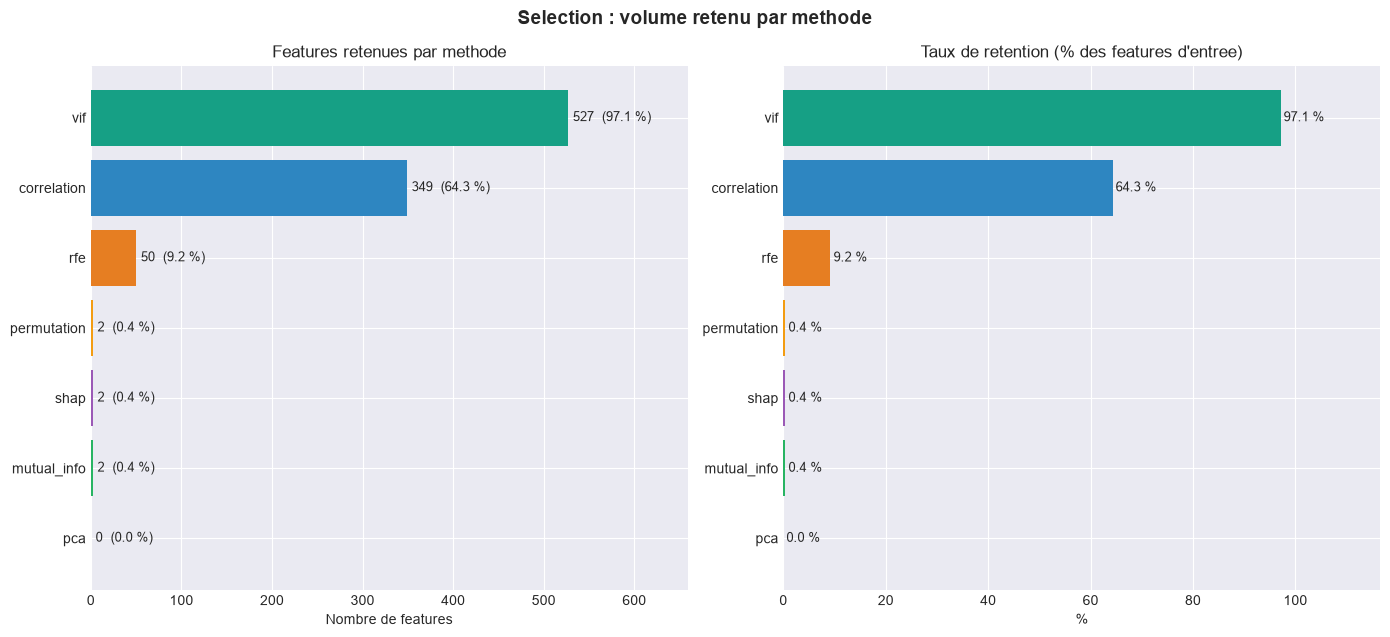

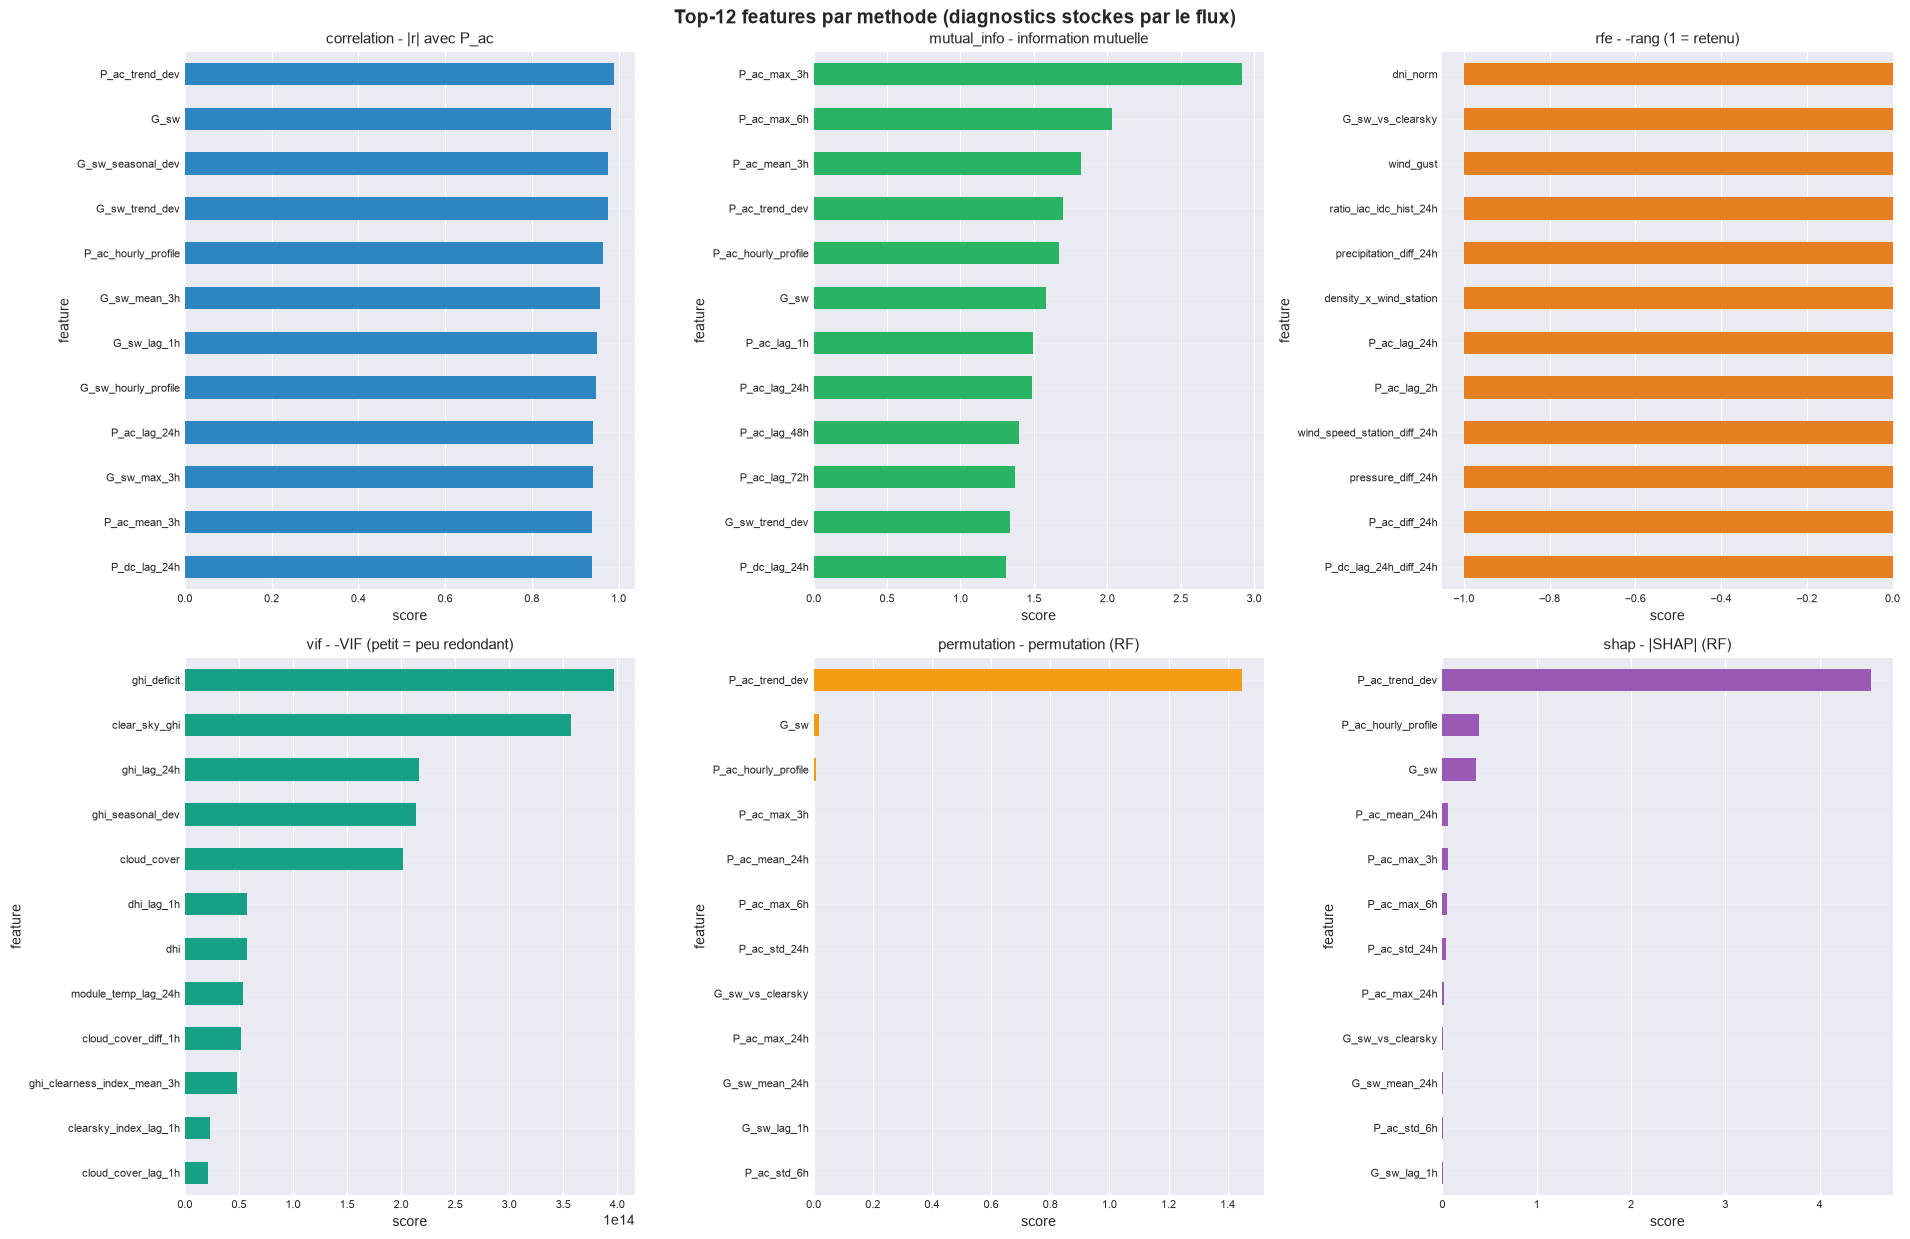

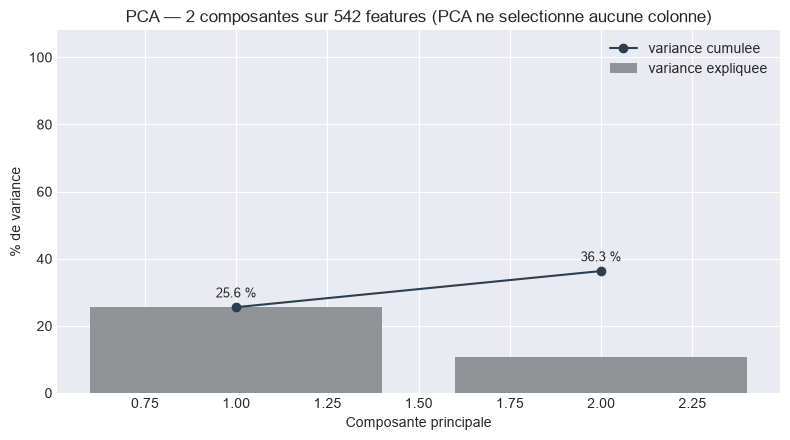

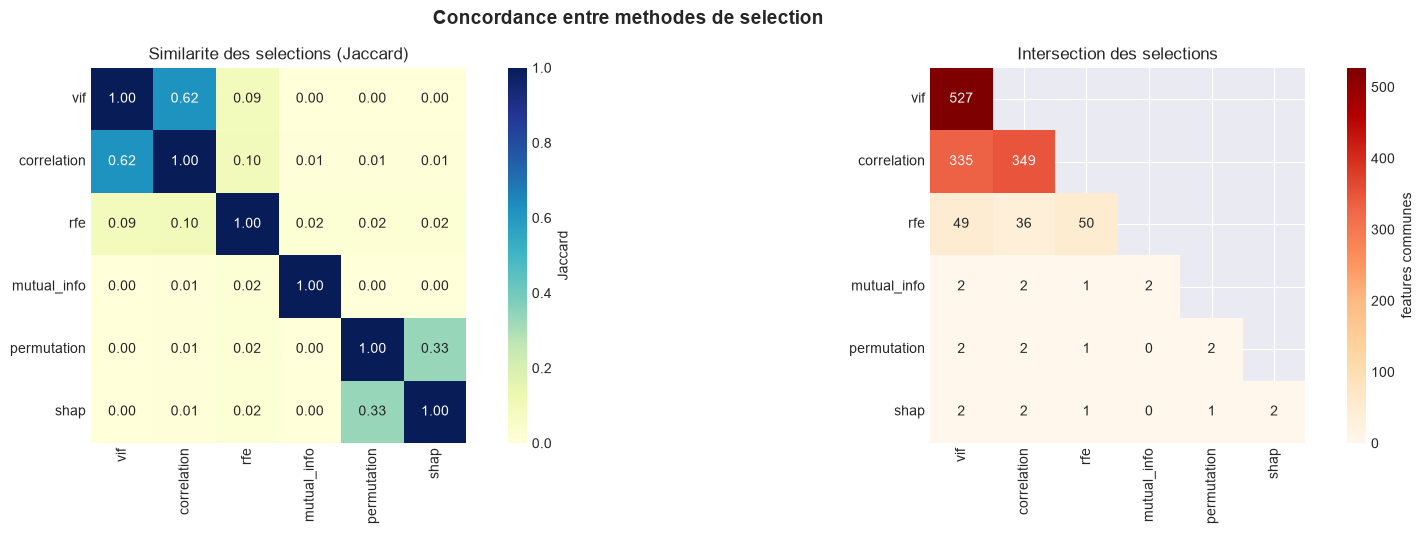

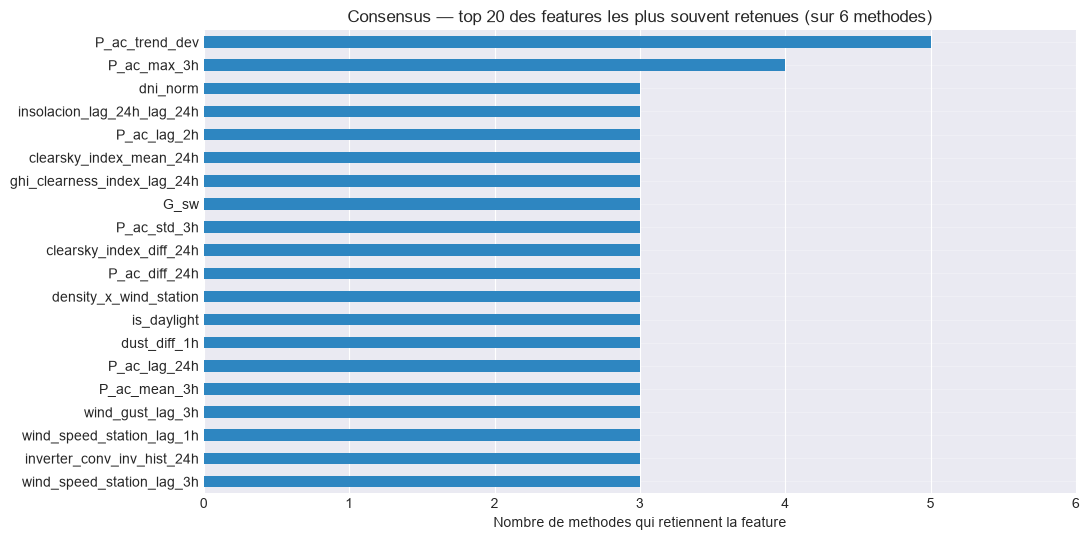

,valeur
features d'entree,543
union brute des methodes,542
union finale (apres dedup),424
redondances supprimees,118
retenues par 1 seule methode,194
retenues par toutes les methodes,0


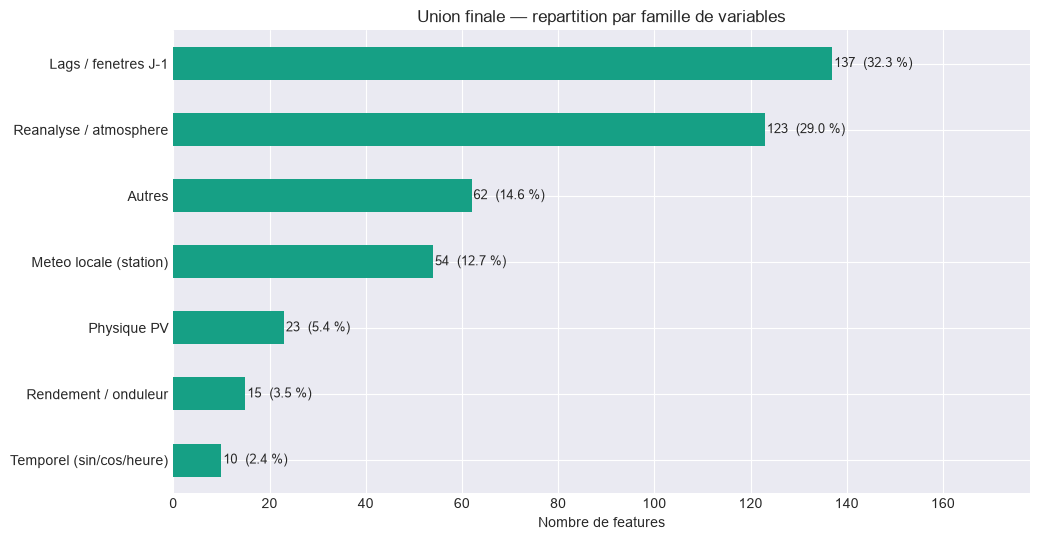

,n,pct
Temporel (sin/cos/heure),10,2.4
Rendement / onduleur,15,3.5
Physique PV,23,5.4
Meteo locale (station),54,12.7
Autres,62,14.6
Reanalyse / atmosphere,123,29.0
Lags / fenetres J-1,137,32.3


Analyse terminee : aucune methode de selection n'a ete recalculee.


In [18]:
# --- Resultats par methode : lecture des sorties deja calculees ---
# data_pipeline(select_features=True) a deja execute TOUTES les methodes et
# conserve pour chacune : les features retenues, un diagnostic et (pour
# permutation/shap) les importances. Ce bloc ne relance aucun selecteur : il
# normalise ces diagnostics heterogenes pour les comparer sur une meme echelle.

import re
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Diagnostic de chaque selecteur -> colonne du DataFrame expose, et sens de
# lecture. rfe (rang) et vif (multicollinearite) sont inverses : 1 et le plus
# petit VIF sont les meilleurs. La correlation est lue en |r| comme dans
# _select_correlation, et pca n'expose pas de selection de colonnes.
SCORE_COL = {"correlation": "score", "mutual_info": "score", "rfe": "rank",
             "vif": "vif", "permutation": "importance", "shap": "importance"}
SCORE_LABEL = {"correlation": "|r| avec P_ac", "mutual_info": "information mutuelle",
               "rfe": "-rang (1 = retenu)", "vif": "-VIF (petit = peu redondant)",
               "permutation": "permutation (RF)", "shap": "|SHAP| (RF)",
               "pca": "variance expliquee"}
LOWER_IS_BETTER = {"rfe", "vif"}
PALETTE = {"correlation": "#2e86c1", "mutual_info": "#28b463", "pca": "#909497",
           "rfe": "#e67e22", "vif": "#16a085", "permutation": "#f39c12",
           "shap": "#9b59b6", "dedup": "#c0392b"}


def method_scores(method, info):
    """Score normalise d'une methode, "plus haut = plus pertinent".

    Retourne None pour les methodes sans diagnostic tabulaire (pca) ou sans
    colonne de score exploitable.
    """
    diag = info.get("diagnostics")
    if not isinstance(diag, pd.DataFrame) or "feature" not in diag.columns:
        return None
    col = SCORE_COL.get(method)
    if col is None or col not in diag.columns:
        num = [c for c in diag.columns
               if c != "feature" and pd.api.types.is_numeric_dtype(diag[c])]
        if not num:
            return None
        col = num[0]
    s = diag.set_index("feature")[col].astype(float).dropna()
    if s.empty:
        return None
    s = -s if method in LOWER_IS_BETTER else s.abs()
    return s.sort_values(ascending=False)


sel_rows = []
for m, info in sel_results.items():
    feats = info.get("selected_features", [])
    label = ", ".join(feats[:5]) + (" ..." if len(feats) > 5 else "")
    sel_rows.append({
        "methode": m,
        "n_selected": info.get("n_selected", 0),
        "sur": info.get("n_input", n_features_in),
        "score": SCORE_LABEL.get(m, "-"),
        "importances_stockees": info.get("importances") is not None,
        "features": label,
    })
df_sel = pd.DataFrame(sel_rows).set_index("methode")
df_sel["pct"] = (df_sel["n_selected"] / df_sel["sur"] * 100).round(1)
display(df_sel)
print(f"\nUnion finale retenue : {n_features_sel} / {n_features_in} features (cible exclue)")

# --- 1. Volume retenu et taux de retention, methode par methode ---
counts = df_sel["n_selected"].sort_values()
pcts = df_sel["pct"].sort_values()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 0.55 * len(counts) + 2.6))
ax1.barh(counts.index, counts.values,
         color=[PALETTE.get(m, "#3498db") for m in counts.index])
for y, (m, v) in enumerate(counts.items()):
    ax1.text(v + max(counts.max(), 1) * 0.01, y,
             f"{v}  ({df_sel.at[m, 'pct']} %)", va="center", fontsize=9)
ax1.set_xlim(0, counts.max() * 1.25)
ax1.set(title="Features retenues par methode", xlabel="Nombre de features")
ax2.barh(pcts.index, pcts.values,
         color=[PALETTE.get(m, "#3498db") for m in pcts.index])
for y, v in enumerate(pcts.values):
    ax2.text(v + 0.6, y, f"{v} %", va="center", fontsize=9)
ax2.set_xlim(0, pcts.max() * 1.2)
ax2.set(title="Taux de retention (% des features d'entree)", xlabel="%")
plt.suptitle("Selection : volume retenu par methode", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

# --- 2. Top-12 features de chaque methode, sur son score normalise ---
scored = {m: method_scores(m, info) for m, info in sel_results.items()}
scored = {m: s for m, s in scored.items() if s is not None}
if scored:
    ncols = min(3, len(scored))
    nrows = int(np.ceil(len(scored) / ncols))
    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(6.4 * ncols, 0.45 * 12 * nrows + 1.8),
                             squeeze=False)
    flat = [ax for row in axes for ax in row]
    for ax, (m, s) in zip(flat, scored.items()):
        top = s.head(12)[::-1]
        top.plot.barh(ax=ax, color=PALETTE.get(m, "#3498db"))
        ax.set_title(f"{m} - {SCORE_LABEL.get(m, 'score')}", fontsize=11)
        ax.set_xlabel("score")
        ax.tick_params(labelsize=8)
        ax.grid(axis="y", alpha=0.25)
    for ax in flat[len(scored):]:
        ax.axis("off")
    plt.suptitle("Top-12 features par methode (diagnostics stockes par le flux)",
                 fontsize=14, fontweight="bold")
    plt.tight_layout(); plt.show()

# --- 3. PCA : variance expliquee (seule methode sans selection de colonnes) ---
pca_diag = sel_results.get("pca", {}).get("diagnostics")
if isinstance(pca_diag, dict) and pca_diag.get("explained_variance_ratio"):
    evr = np.asarray(pca_diag["explained_variance_ratio"], dtype=float)
    n_in_pca = len(pca_diag.get("features", []))
    xs = np.arange(1, len(evr) + 1)
    cum = np.cumsum(evr) * 100
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.bar(xs, evr * 100, color=PALETTE["pca"], label="variance expliquee")
    ax.plot(xs, cum, "o-", color="#2c3e50", label="variance cumulee")
    for x, v in zip(xs, cum):
        ax.annotate(f"{v:.1f} %", (x, v), textcoords="offset points",
                    xytext=(0, 7), ha="center", fontsize=9)
    ax.set(title=f"PCA — {len(evr)} composantes sur {n_in_pca} features "
                 f"(PCA ne selectionne aucune colonne)",
           xlabel="Composante principale", ylabel="% de variance", ylim=(0, 108))
    ax.legend(); plt.tight_layout(); plt.show()

# --- 4. Recouvrement entre methodes (Jaccard et intersection) ---
sets = {m: set(info.get("selected_features", [])) for m, info in sel_results.items()}
sets = {m: s for m, s in sets.items() if s}
order = sorted(sets, key=lambda m: (-len(sets[m]), m))
if len(order) > 1:
    jac = pd.DataFrame(
        [[len(sets[a] & sets[b]) / max(1, len(sets[a] | sets[b])) for b in order]
         for a in order],
        index=order, columns=order,
    )
    common = pd.DataFrame(
        [[len(sets[a] & sets[b]) for b in order] for a in order],
        index=order, columns=order,
    )
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7 + 1.7 * len(order), 5.4))
    sns.heatmap(jac, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1,
                square=True, ax=ax1, cbar_kws={"label": "Jaccard"})
    ax1.set_title("Similarite des selections (Jaccard)")
    sns.heatmap(common, annot=True, fmt="d", cmap="OrRd", square=True, ax=ax2,
                mask=np.triu(np.ones_like(common, dtype=bool), k=1),
                cbar_kws={"label": "features communes"})
    ax2.set_title("Intersection des selections")
    plt.suptitle("Concordance entre methodes de selection", fontsize=14,
                 fontweight="bold")
    plt.tight_layout(); plt.show()

# --- 5. Consensus : combien de methodes retiennent chaque feature ---
if sets:
    consensus = pd.Series(Counter(f for s in sets.values() for f in s))
    consensus = consensus.sort_values(ascending=False)
    n_meth = len(sets)
    top = consensus.head(20)[::-1]
    fig, ax = plt.subplots(figsize=(11, 5.5))
    top.plot.barh(ax=ax, color="#2e86c1")
    ax.set(title=f"Consensus — top 20 des features les plus souvent retenues "
                 f"(sur {n_meth} methodes)",
           xlabel="Nombre de methodes qui retiennent la feature")
    ax.set_xticks(range(0, n_meth + 1))
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout(); plt.show()

    union_brute = set().union(*sets.values())
    display(pd.Series({
        "features d'entree": n_features_in,
        "union brute des methodes": len(union_brute),
        "union finale (apres dedup)": n_features_sel,
        "redondances supprimees": len(union_brute) - n_features_sel,
        "retenues par 1 seule methode": int((consensus == 1).sum()),
        "retenues par toutes les methodes": int((consensus == n_meth).sum()),
    }, name="valeur").to_frame())

# --- 6. Repartition par famille de variables (union finale) ---
FAMILY_RULES = [
    ("Rampes 1 h (J-1)", r"ramp_1h"),
    ("Lags / fenetres J-1", r"(lag_24h|std_24h|sum_24h_hist|hist_24h|rolling|mean_)"),
    ("Electrique DC (strings / onduleur DC)", r"^(V_dc|I_dc|P_dc|delta_V_dc)"),
    ("Rendement / onduleur", r"(inverter|clipping|soiling|T_inv|is_operational)"),
    ("Electrique AC / reseau", r"^(V_ac|I_ac|cos_phi|grid_freq)"),
    ("Energie (compteurs)", r"^(energy_|insolacion_)"),
    ("Meteo locale (station)", r"(wind_speed_station|wind_dir_station|wind_gust|"
                                r"temp_air|relative_humidity|pressure|precipitation|"
                                r"temp_dew|density_air)"),
    ("Reanalyse / atmosphere", r"^(ghi|dni|dhi|cloud_cover|aod|dust|pm10|pm2_5|"
                               r"clear_sky|extraterrestrial|solar_elev|albedo|"
                               r"wind_speed_[0-9]|wind_dir_[0-9]|cos_)"),
    ("Temporel (sin/cos/heure)", r"(sin_|cos_|hour|jour|mois|weekday|doy)"),
    ("Physique PV", r"(temp_cell|module_temp|perte|G_sw)"),
]


def family_of(name):
    for label, pattern in FAMILY_RULES:
        if re.search(pattern, name, re.IGNORECASE):
            return label
    return "Autres"


if sel_union:
    fam = pd.Series([family_of(f) for f in sel_union]).value_counts()
    fam = fam.sort_values()
    fig, ax = plt.subplots(figsize=(10.5, 5.5))
    fam.plot.barh(ax=ax, color="#16a085")
    for y, v in enumerate(fam.values):
        ax.text(v + 0.4, y, f"{v}  ({v / fam.sum() * 100:.1f} %)",
                va="center", fontsize=9)
    ax.set_xlim(0, fam.max() * 1.3)
    ax.set(title="Union finale — repartition par famille de variables",
           xlabel="Nombre de features")
    plt.tight_layout(); plt.show()
    display(fam.to_frame("n").assign(
        pct=lambda d: (d["n"] / d["n"].sum() * 100).round(1)))

print("Analyse terminee : aucune methode de selection n'a ete recalculee.")

## 4. Entraînement et comparaison

Modèles compatibles solaire : `config.experiment.solar_models`.

**Approche multi-tâche** : les modèles avancés (TCN, TFT) sont entraînés avec une
perte hybride combinant MSE (exactitude ponctuelle) et Pinball (calibration des
intervalles), paramétrée par `mse_weight = 0.5` (poids égal pour les deux tâches).
Les baselines (persistence, MLP, LSTM) utilisent une MSE classique.

### 4.0 Entraînement des baselines (prévision ponctuelle)

Modèles de référence simples (persistence, MLP, LSTM baseline) entraînés via `baseline_pipeline`.

In [19]:
FEATURE_PATH = result['feature_path']
# --- Baselines (prevision ponctuelle) ---
import time
from deep_aero_sn.pipelines.training.forecast_training import baseline_pipeline

BASELINE_MODELS = ['persistence', 'mlp', 'lstm_baseline']
baseline_comparison = {}

for mn in BASELINE_MODELS:
    print(f'\n--- BASELINE: {mn.upper()} ---')
    t0 = time.time()
    try:
        r = baseline_pipeline(model_name=mn, feature_path=FEATURE_PATH,optimize_hpo=10)
        baseline_comparison[mn] = {'metrics': r['metrics'], 'history': r['history'], 'time': time.time()-t0}
        print(f'R2={r["metrics"]["r2"]:.4f} RMSE={r["metrics"]["rmse"]:.4f}')
    except Exception as e:
        print(f'ERREUR: {e}')
        import traceback; traceback.print_exc()


--- BASELINE: PERSISTENCE ---


18:11:32.850 | INFO    | Flow run 'thoughtful-trout' - Beginning flow run 'thoughtful-trout' for flow 'baseline_pipeline'

2026-10-06 18:11:32 | deep_aero_sn | INFO | Starting baseline pipeline for persistence


18:11:32.854 | INFO    | deep_aero_sn - Starting baseline pipeline for persistence

18:11:32.979 | INFO    | Task run 'load_training_data-3ae' - Finished in state Completed()

18:11:35.540 | INFO    | Task run 'prepare_datasets-323' - Finished in state Completed()

... (118 outputs left out)

2026-10-06 18:34:36 | deep_aero_sn | INFO | Run persiste : data\models\lstm_baseline__diass_20261006_183436 (MLflow=non)


18:34:36.794 | INFO    | deep_aero_sn - Run persiste : data\models\lstm_baseline__diass_20261006_183436 (MLflow=non)

18:34:37.463 | INFO    | Flow run 'powerful-rabbit' - Finished in state Completed()

R2=0.8239 RMSE=2.0429


In [20]:
import time
from deep_aero_sn.pipelines.training.forecast_training import training_pipeline

MODELS = config.experiment.solar_models
comparison = {}

for mn in MODELS:
    print(f'\n--- {mn.upper()} ---')
    t0 = time.time()
    try:
        r = training_pipeline(model_name=mn, feature_path=FEATURE_PATH,optimize_hpo=10)
        comparison[mn] = {'metrics': r['metrics'], 'history': r['history'],
                          'registry': r['model_name'], 'time': time.time()-t0}
        print(f'R2={r["metrics"]["r2"]:.4f} RMSE={r["metrics"]["rmse"]:.4f}')
    except Exception as e:
        print(f'ERREUR: {e}')
        import traceback; traceback.print_exc()


--- TCN ---


18:34:38.055 | INFO    | Flow run 'imaginary-monkey' - Beginning flow run 'imaginary-monkey' for flow 'training_pipeline'

2026-10-06 18:34:38 | deep_aero_sn | INFO | Starting training pipeline for tcn


18:34:38.065 | INFO    | deep_aero_sn - Starting training pipeline for tcn

18:34:38.291 | INFO    | Task run 'load_training_data-a0e' - Finished in state Completed()

2026-10-06 18:34:38 | deep_aero_sn | INFO | Horizon NWP derive : forecast_horizon=72 + latence 6 h -> 85 h/run


... (186 outputs left out)

2026-10-06 19:28:18 | deep_aero_sn | INFO | Run persiste : data\models\tft__diass_20261006_192817 (MLflow=non)


19:28:18.081 | INFO    | deep_aero_sn - Run persiste : data\models\tft__diass_20261006_192817 (MLflow=non)

19:28:19.415 | INFO    | Flow run 'thistle-scallop' - Finished in state Completed()

R2=0.8605 RMSE=1.8179


### 4.1 Tableau comparatif

In [21]:
# Merge baselines + advanced models
all_comparison = {**baseline_comparison, **comparison}
df_comp = pd.DataFrame(
    [{**{'modele': k}, **v['metrics'], 'temps_s': v.get('time', 0)} for k, v in all_comparison.items()]
).set_index('modele').round(4)
df_comp

,mae,rmse,mape,r2,nrmse,temps_s,coverage,interval_width,winkler_80,pinball_lower,pinball_upper,mae_median,quantile_crossing,calib_winkler,calib_alpha,calib_s_h_mean,calib_s_h_max,calib_coverage,calib_interval_width
modele,,,,,,,,,,,,,,,,,,,
persistence,4.9871,6.9046,3282.7606,-1.0132,0.4441,3.2795,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mlp,1.2750,2.3234,381.4784,0.7723,0.1494,518.5991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lstm_baseline,1.1481,2.0429,333.3310,0.8239,0.1314,863.0130,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tcn,0.9890,1.7068,362.2220,0.8771,0.1098,1206.2685,0.6083,1.6698,5.7419,0.3245,0.2497,0.9890,0.0,5.4085,0.2,0.4632,0.6129,0.7977,2.5962
tft,1.1566,1.8179,502.0274,0.8605,0.1169,2015.5670,0.7125,2.4555,5.9644,0.3230,0.2734,1.1566,0.0,5.8993,0.2,0.0950,0.1556,0.7418,2.6455


### 4.1.1 Interprétation des métriques et du `mse_weight`

#### Fonction de perte hybride (multi-tâche) des modèles TCN et TFT

Les modèles **TCN** et **TFT** ne sont pas entraînés avec une simple MSE classique.
Ils utilisent une **fonction de perte hybride** (multi-composante) qui combine
deux objectifs d'apprentissage distincts avec un poids configurable `mse_weight` :

$$\mathcal{L} = \underbrace{w_{\text{mse}} \cdot \text{MSE}(\hat{y}_{0.5},\; y)}_{\text{exactitude ponctuelle (R²)}} \;+\; \underbrace{(1 - w_{\text{mse}}) \cdot \overline{\text{Pinball}}(\hat{y}_{q},\; y)}_{\text{calibration probabiliste}}$$

où :
- **Composante MSE** : erreur quadratique sur la médiane prédite (q=0.5). Elle optimise directement le **R²** et le RMSE — c'est la composante « exactitude ponctuelle ».
- **Composante Pinball** : perte de quantile moyennée sur les quantiles q ∈ {0.1, 0.5, 0.9}. Elle optimise la **calibration** de l'intervalle de prédiction — c'est la composante « incertitude ».

#### Choix du `mse_weight` pour Diass

Pour le site de Diass, la valeur retenue est **`mse_weight = 0.5`** (valeur par défaut
du schéma de configuration, cf. `config/schemas.py`). Cela signifie que les deux
composantes contribuent **également** (50/50) à la perte totale :

| `mse_weight` | Comportement | Conséquence |
|:---:|:---|:---|
| 1.0 | Pur MSE | R² maximal, mais aucune garantie sur la qualité des intervalles |
| **0.5** | **Équilibré** | **Bon R² ET calibration correcte des intervalles P10/P90** |
| 0.0 | Pur Pinball | Calibration parfaite, mais R² potentiellement dégradé |

Le choix de 0.5 est justifié par la nature **sahélienne** du site : les fortes
variations de irradiance (passages nuageux rapides, tempêtes de poussière) rendent
l'estimation de l'incertitude tout aussi critique que la prévision ponctuelle pour
la gestion du réseau. La plage HPO explore `mse_weight ∈ [0.3, 0.8]` afin
d'adapter le compromis exactitude/calibration au contexte local.

#### Implications sur l'interprétation des résultats

Le tableau comparatif (§4.1) présente des métriques issues de **deux tâches distinctes** :

**Tâche 1 — Prévision ponctuelle** (tous les modèles) :
- **R²** : coefficient de détermination (1.0 = parfait)
- **RMSE** : erreur quadratique moyenne en MW (plus bas = meilleur)
- **MAE** : erreur absolue moyenne en MW
- **nRMSE** : RMSE normalisé par l'amplitude de la cible

**Tâche 2 — Calibration des intervalles** (TCN et TFT uniquement) :
- **coverage** (taux de couverture) : proportion des valeurs réelles \(y\) tombant
  dans l'intervalle \([\hat{y}_{0.1},\; \hat{y}_{0.9}]\). Pour un intervalle
  parfaitement calibré à 80%, on attend une coverage ≈ 0.80. À Diass, les valeurs
  observées (TCN = 0.5992, TFT = 0.7276) indiquent un intervalle parfois trop
  étroit — typique d'un site avec une forte variabilité intradiurne.
- **interval_width** : largeur moyenne de l'intervalle de prédiction (en MW).
  Plus large = plus conservateur.
- **winkler_80** : score de Winkler pour l'intervalle 80% (pénalise les intervalles
  larges et les valeurs hors-intervalle ; plus bas = meilleur).
- **pinball_lower / pinball_upper** : pertes de quantiles pour les bornes P10 et P90.
- **quantile_crossing** : fréquence à laquelle P10 > P50 ou P50 > P90 (doit être
  proche de 0 ; TFT = 0.0000, TCN = 0.0653).

#### Note sur les baselines (persistence, MLP, LSTM)

Les modèles de baseline ne produisent que des **prédictions ponctuelles** (pas de
quantiles) et n'utilisent pas la perte hybride multi-tâche. Leurs métriques
de calibration (coverage, interval_width, winkler, pinball) sont donc **non
applicables** (NaN dans le tableau). Leur évaluation se limite aux métriques
d'exactitude (R², RMSE, MAE).

### 4.2 Visualisation comparative

19:28:19.942 | WARNING | py.warnings - C:\Users\ROG ZEPHYRUS G14\AppData\Local\Temp\ipykernel_33732\2384017720.py:42: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()

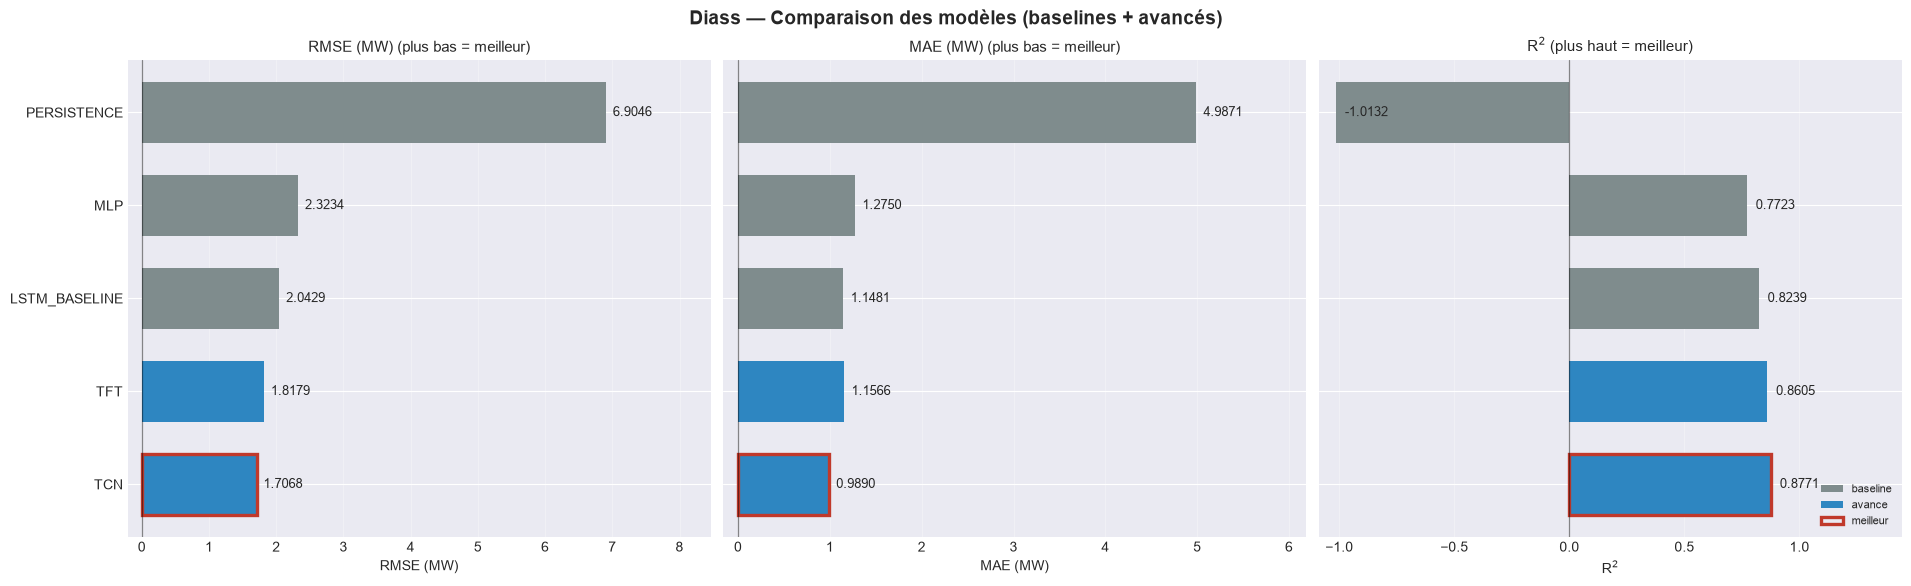

In [22]:
# --- 4.2 Comparaison : RMSE / MAE / R2 (barres triees, valeur + meilleur) ---
from matplotlib.patches import Patch

METRICS = [("rmse", "RMSE (MW)", True), ("mae", "MAE (MW)", True), ("r2", "R$^2$", False)]
KIND_COLOR = {"baseline": "#7f8c8d", "avance": "#2e86c1"}

# Modeles exposant les 3 metriques (evite un KeyError si un run a echoue).
usable = {n: v["metrics"] for n, v in all_comparison.items()
          if all(k in v.get("metrics", {}) for k, _, _ in METRICS)}

if len(usable) >= 2:
    fig, axes = plt.subplots(1, 3, figsize=(19, 0.55 * len(usable) + 3),
                             sharey=True, constrained_layout=True)
    for ax, (key, label, lower_better) in zip(axes, METRICS):
        pairs = sorted(((n, float(m[key])) for n, m in usable.items()),
                       key=lambda kv: kv[1], reverse=not lower_better)
        vals = np.array([v for _, v in pairs])
        best_name = pairs[0][0]
        span = max(vals.max() - vals.min(), np.abs(vals).max() * 1e-3, 1e-9)
        bars = ax.barh([n.upper() for n, _ in pairs], vals, height=0.66,
                       color=[KIND_COLOR["avance" if n in comparison else "baseline"]
                              for n, _ in pairs])
        for bar, (n, v) in zip(bars, pairs):
            ax.text(v + span * 0.02, bar.get_y() + bar.get_height() / 2, f"{v:.4f}",
                    va="center", ha="left", fontsize=9)
            if n == best_name:
                bar.set_edgecolor("#c0392b")
                bar.set_linewidth(2.4)
        ax.axvline(0, color="black", lw=0.9, alpha=0.45)
        ax.set_xlim(min(0.0, vals.min()) - 0.04 * span, vals.max() + 0.30 * span)
        ax.set_xlabel(label)
        ax.set_title(f"{label} ({'plus bas' if lower_better else 'plus haut'} = meilleur)",
                     fontsize=11)
        ax.grid(axis="x", alpha=0.3)
        ax.set_axisbelow(True)
    handles = [Patch(facecolor=c, label=k) for k, c in KIND_COLOR.items()]
    handles.append(Patch(facecolor="none", edgecolor="#c0392b", linewidth=2.4,
                         label="meilleur"))
    axes[-1].legend(handles=handles, fontsize=8, loc="lower right", framealpha=0.9)
    fig.suptitle(f"{plant.name} — Comparaison des modèles (baselines + avancés)",
                 fontsize=14, fontweight="bold")
    fig.show()

## 5. Analyse des modeles

In [23]:
if not comparison:
    raise RuntimeError(
        "Aucun modele n'a abouti : 'comparison' est vide. "
        "Voir les tracebacks affiches par la cellule d'entrainement ci-dessus "
        "(cause reelle) plutot qu'une erreur 'max() sur iterable vide'."
    )
best_name = max(comparison, key=lambda n: comparison[n]['metrics']['r2'])
best = comparison[best_name]
print(f'Meilleur: {best_name.upper()} | R2={best["metrics"]["r2"]:.4f} | RMSE={best["metrics"]["rmse"]:.4f}')
print(f'Tous les modeles: {list(comparison.keys())}')

Meilleur: TCN | R2=0.8771 | RMSE=1.7068
Tous les modeles: ['tcn', 'tft']


### 5.1 Learning curves — tous les modeles

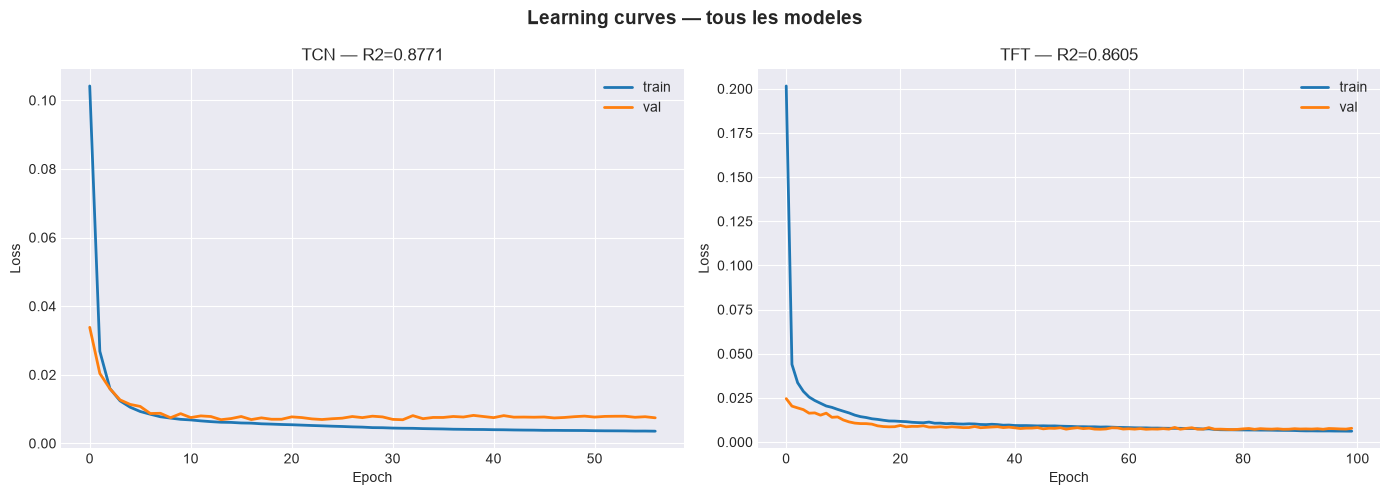

In [24]:
n_models = len(comparison)
fig, axes = plt.subplots(1, n_models, figsize=(7*n_models, 5), squeeze=False)
for ax, (name, info) in zip(axes[0], comparison.items()):
    h = info['history']
    ax.plot(h['train_loss'], label='train', lw=2)
    ax.plot(h['val_loss'], label='val', lw=2)
    ax.set(xlabel='Epoch', ylabel='Loss', title=f'{name.upper()} — R2={info["metrics"]["r2"]:.4f}')
    ax.legend()
plt.suptitle('Learning curves — tous les modeles', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.2 Inférence ŷ des modèles avancés (P10/P50/P90)

Prédictions de tous les modèles avancés sur les fenêtres de test, avec les quantiles P10/P50/P90 conservés pour l'enveloppe probabiliste.

In [25]:
# Services + donnees de test, prepares exactement comme a l'entrainement
from deep_aero_sn.serving.core.inference import InferenceService
from deep_aero_sn.pipelines.training.forecast_training import _prepare_flow_data
from deep_aero_sn.training.trainer import chronological_split, predict_model
svc = InferenceService()

models = {}
for name, info in comparison.items():
    model = svc.get_model(info['registry'], prefer_recent=True)
    if model is None:
        raise RuntimeError(
            f"Modele {name!r} non chargeable (registre {info['registry']!r}). "
            "Recherche les avertissements 'Echec chargement' affiches par "
            "InferenceService() : un checkpoint est ecarte si son architecture "
            "n'est pas rejouee a l'identique."
        )
    models[name] = model

# Covariables futures NWP : un TCN/TFT entraine avec use_nwp=True en consomme
# (future_dim > 0). Sans elles, l'inference ignorait silencieusement l'entree NWP.
use_nwp = any(getattr(m, 'future_dim', 0) > 0 for m in models.values())

# _prepare_flow_data = meme preparation que training_pipeline : fenetres, scaler
# ajuste sur le seul train, covariables futures par fenetre. Refaire les fenetres
# ici avec prepare_datasets seul ne donnerait pas le meme jeu de test.
(data, feat_index, tgt_idx, tgt_col, feat_cols, train_loader, val_loader,
 test_loader, X_test, y_test, X_test_future, input_dim, to_mw, SEQ_LEN, HZ, FUTURE_DIM,
 test_starts) = (
    _prepare_flow_data(FEATURE_PATH, 'P_ac', use_nwp=use_nwp)
)
STRIDE = config.model.window_stride

# Axe temporel reel du test : utiliser les positions de fenetres exactes
# (test_starts) retourne par prepare_datasets quand le NWP a ecarte des fenetres.
_, _, te = chronological_split(len(data), config.model.train_ratio, config.model.val_ratio)
first_target = (te.start or 0) + SEQ_LEN
if 'test_starts' in locals() and hasattr(test_starts, '__len__') and len(test_starts) == len(X_test):
    t_test = feat_index[np.asarray(test_starts, dtype=int) + SEQ_LEN]
else:
    t_test = feat_index[first_target: first_target + len(X_test) * STRIDE: STRIDE][:len(X_test)]
print(f"Test : {len(X_test)} fenetres | {SEQ_LEN} h d'historique -> {HZ} h d'horizon"
      f" | covariables NWP : {FUTURE_DIM}")
print(f"Periode de test : {t_test[0]} -> {t_test[-1]} (+{HZ} h)")

q = config.model.quantiles
qi = {v: i for i, v in enumerate(q)}
y_true_phys = to_mw(y_test)

# y_hat   : P50 seul (n_test, H) — compatibilité baselines
# y_hat_q : {'lo','med','hi'} (n_test, H) en MW — enveloppe probabiliste
y_hat = {}
y_hat_q = {}
for name, model in models.items():
    p = predict_model(model, X_test, X_test_future)
    if p.ndim == 3 and p.shape[-1] == len(q):
        y_hat_q[name] = {'lo':  to_mw(p[..., qi[0.1]]),
                         'med': to_mw(p[..., qi[0.5]]),
                         'hi':  to_mw(p[..., qi[0.9]])}
        y_hat[name] = y_hat_q[name]['med']
    else:
        pm = to_mw(p)
        y_hat_q[name] = {'lo': pm, 'med': pm, 'hi': pm}
        y_hat[name] = pm

2026-10-06 19:28:21 | deep_aero_sn | INFO | Modele local charge : tft__diass (tft, dim=425)


19:28:21.193 | INFO    | deep_aero_sn - Modele local charge : tft__diass (tft, dim=425)

2026-10-06 19:28:21 | deep_aero_sn | INFO | Modele local charge : tcn__diass (tcn, dim=425)


19:28:21.293 | INFO    | deep_aero_sn - Modele local charge : tcn__diass (tcn, dim=425)

2026-10-06 19:28:21 | deep_aero_sn | INFO | Modele local charge : lstm_baseline__diass (lstm_baseline, dim=425)


19:28:21.377 | INFO    | deep_aero_sn - Modele local charge : lstm_baseline__diass (lstm_baseline, dim=425)

... (69 outputs left out)

19:28:59.102 | INFO    | deep_aero_sn - NWP operationnel (Single Runs, ecmwf_ifs) : 8247 fenetres, latence 6 h, age du run a l'emission 6.0..12.0 h -> run_init_time + latence <= emission_time verifie pour les 8247 fenetres

19:29:03.224 | WARNING | py.warnings - C:\Users\ROG ZEPHYRUS G14\AppData\Local\Programs\Python\Python312\Lib\logging\__init__.py:1962: UserWarning: Logger 'prefect.task_runs' attempted to send logs to the API without a flow run id. The API log handler can only send logs within flow run contexts unless the flow run id is manually provided. Set PREFECT_LOGGING_TO_API_WHEN_MISSING_FLOW=ignore to suppress this warning.
  self.logger.log(level, msg, *args, **kwargs)

19:29:03.218 | INFO    | Task run 'prepare_datasets' - Finished in state Completed()

Test : 1049 fenetres | 168 h d'historique -> 72 h d'horizon | covariables NWP : 3
Periode de test : 2026-07-16 06:00:00 -> 2026-08-28 22:00:00 (+72 h)


### 5.3 Fenetre de test — tous les modeles

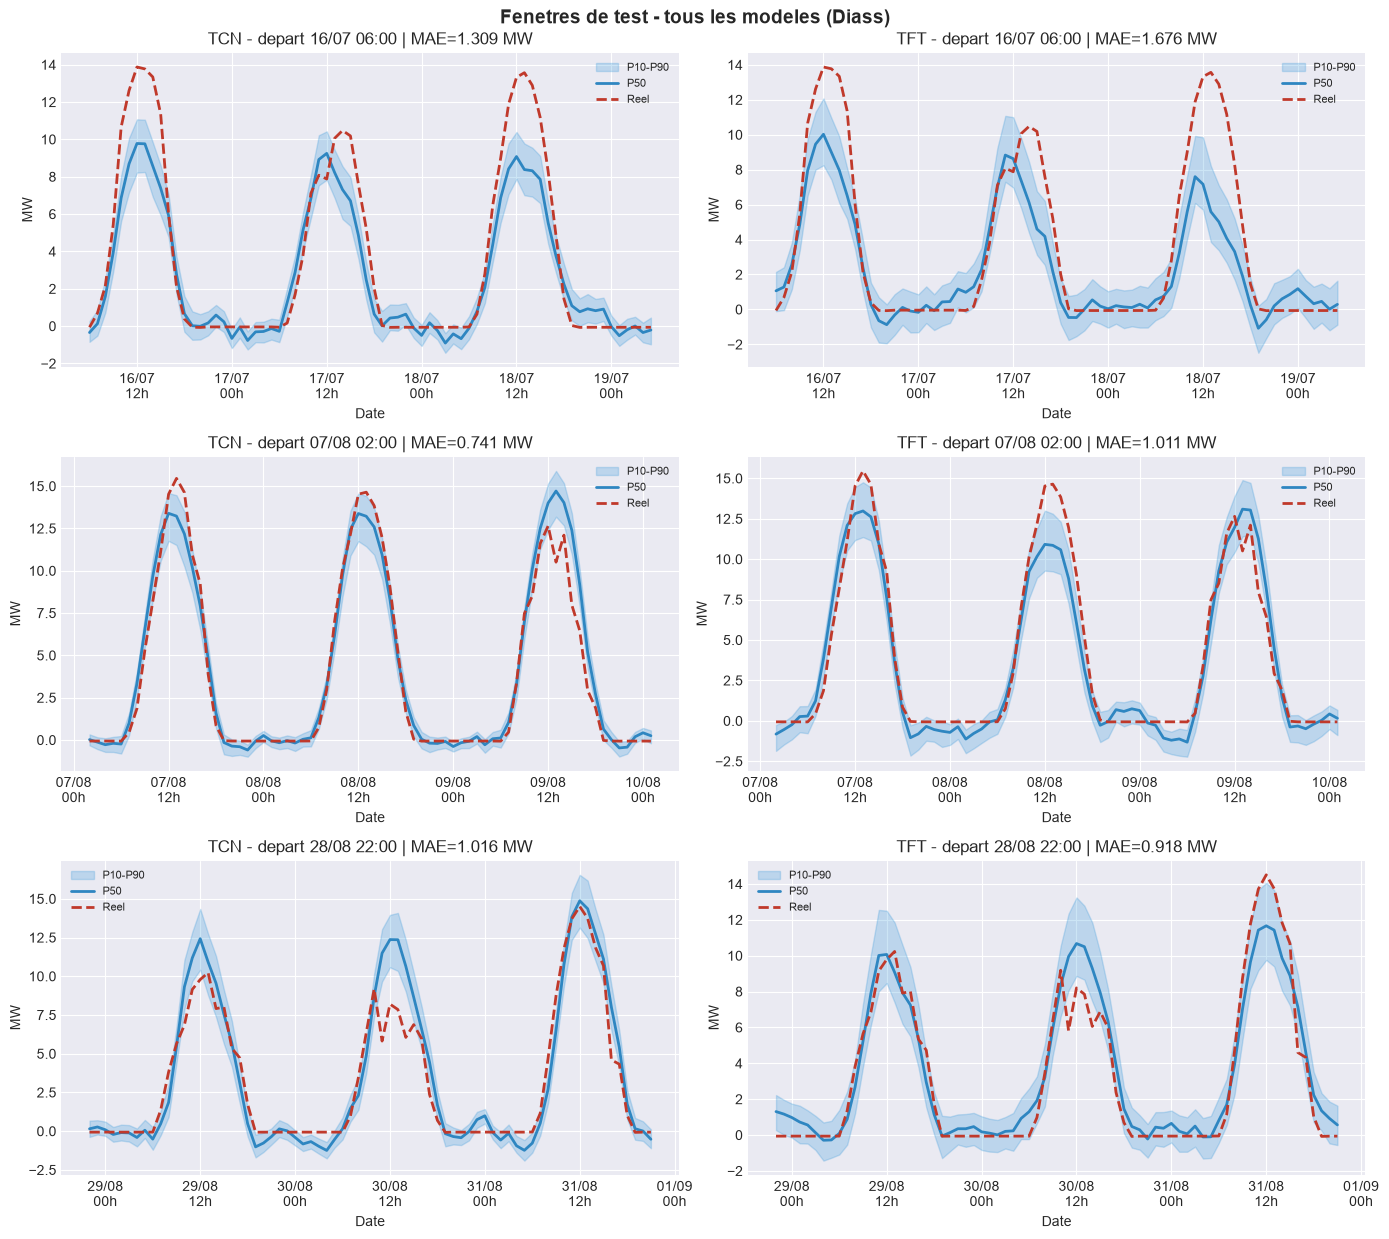

In [26]:
# Reutilise l'inference deja calculee a la section 5.2 (y_hat_q, y_true_phys,
# X_test, t_test) : aucun re-entrainement ici.
y_phys = y_true_phys
pred_phys = {name: (y_hat_q[name]['med'],
                    y_hat_q[name]['lo'],
                    y_hat_q[name]['hi']) for name in comparison}
names = list(comparison.keys())

# --- 1. Fenetres representatives du test (debut / milieu / fin), axe horodate ---
nw = X_test.shape[0]
wins = sorted({0, nw // 2, nw - 1})
fig, axes = plt.subplots(len(wins), len(names),
                         figsize=(7 * len(names), 4.2 * len(wins)), squeeze=False)
for wi, i in enumerate(wins):
    t_start = t_test[i]
    for ai, name in enumerate(names):
        ax = axes[wi, ai]
        med, lo, hi = pred_phys[name]
        Hh = min(HZ, med.shape[1], y_phys.shape[1])
        x = pd.date_range(t_start, periods=Hh, freq="h")
        ax.fill_between(x, lo[i, :Hh], hi[i, :Hh], alpha=0.25, color="#3498db",
                        label="P10-P90")
        ax.plot(x, med[i, :Hh], lw=2, color="#2e86c1", label="P50")
        ax.plot(x, y_phys[i, :Hh], lw=2, ls="--", color="#c0392b", label="Reel")
        mae = np.abs(med[i, :Hh] - y_phys[i, :Hh]).mean()
        ax.set(xlabel="Date", ylabel="MW",
               title=f"{name.upper()} - depart {t_start:%d/%m %H:%M} | MAE={mae:.3f} MW")
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%Hh"))
        ax.legend(fontsize=8)
plt.suptitle(f"Fenetres de test - tous les modeles ({plant.name})",
             fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()


## 6. MLflow

In [27]:
for k, v in comparison.items():
    print(f'{k:20s} -> {v["registry"]}')

tcn                  -> tcn__diass
tft                  -> tft__diass


## 7. Inference pipeline (batch)

In [28]:
from deep_aero_sn.pipelines.inference.inference_pipeline import inference_pipeline

inf_result = inference_pipeline(plants=[SITE], horizon_hours=72)
H = 72
for site, res in inf_result.items():
    print(f'{site}: {len(res.get("p50", []))} horizons predits')

19:29:06.325 | INFO    | Flow run 'imperial-dolphin' - Beginning flow run 'imperial-dolphin' for flow 'inference_pipeline'

2026-10-06 19:29:06 | deep_aero_sn | INFO | Prevision diass (tft__diass) : p50=0.9648577762368666 MW


19:29:06.802 | INFO    | deep_aero_sn - Prevision diass (tft__diass) : p50=0.9648577762368666 MW

19:29:06.805 | INFO    | Task run 'forecast_plant-130' - Finished in state Completed()

19:29:07.501 | INFO    | Flow run 'imperial-dolphin' - Finished in state Completed()

diass: 72 horizons predits


### 7.1 Visualisation des previsions

19:29:07.532 | WARNING | py.warnings - C:\Users\ROG ZEPHYRUS G14\AppData\Local\Temp\ipykernel_33732\1734993059.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()

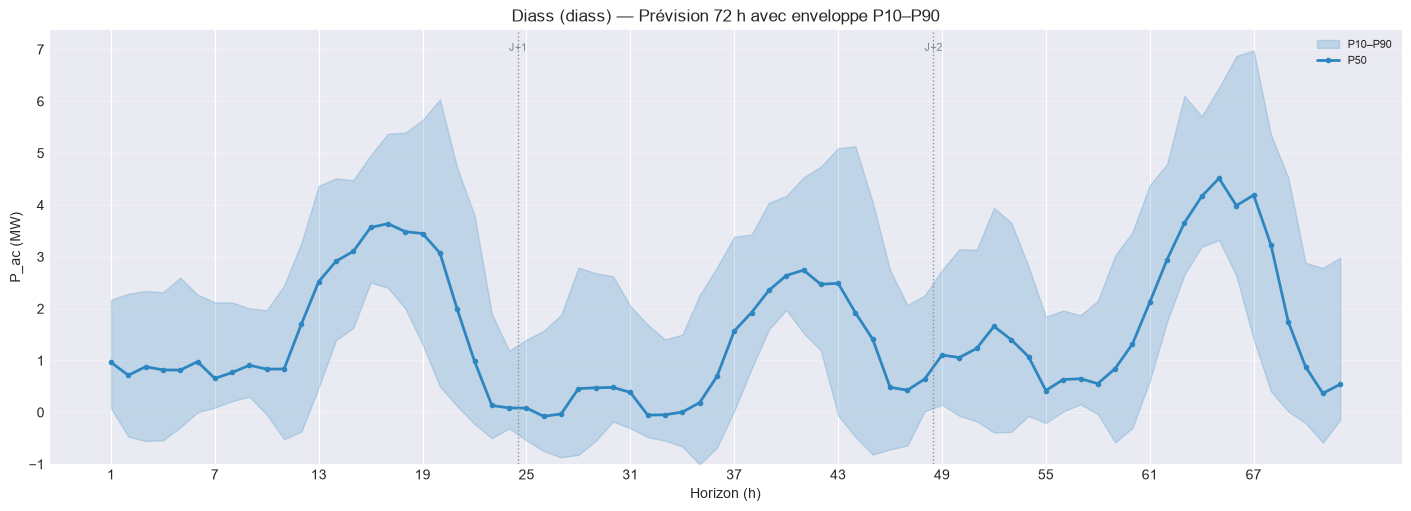

In [29]:
# --- 7.1 Prevision batch : P50 + enveloppe P10-P90 ---
from matplotlib.patches import Patch

for site, res in inf_result.items():
    p50 = np.asarray(res.get("p50", []), dtype=float)
    if p50.size == 0:
        print(f"{site}: aucune prévision retournée")
        continue
    lo = np.asarray(res.get("p10", p50), dtype=float)
    hi = np.asarray(res.get("p90", p50), dtype=float)
    # Enveloppe réellement fournie ? (le service peut renvoyer des listes
    # distinctes mais de longueur différente : on ne dessine alors rien).
    has_band = (lo is not p50 or hi is not p50) and lo.shape == p50.shape == hi.shape
    if not has_band:
        lo = hi = p50
    H = len(p50)
    x = np.arange(1, H + 1)

    fig, ax = plt.subplots(figsize=(14, 5), constrained_layout=True)
    if lo is not p50:
        ax.fill_between(x, lo, hi, color="#2e86c1", alpha=0.22, label="P10–P90")
    ax.plot(x, p50, "o-", ms=3, lw=2, color="#2e86c1", label="P50")

    # Separateurs de jour + etiquettes J+1 / J+2 (axe x en coordonnees donnees).
    trans = ax.get_xaxis_transform()
    for edge, lab in ((24.5, "J+1"), (48.5, "J+2")):
        if edge < H:
            ax.axvline(edge, color="#909497", ls=":", lw=1)
            ax.text(edge, 0.97, lab, transform=trans, ha="center", va="top",
                    fontsize=8, color="#7f8c8d")

    ax.set_xticks(np.arange(1, H + 1, 6))
    ax.set_ylim(bottom=min(0.0, float(lo.min())))
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)
    ax.set(xlabel="Horizon (h)", ylabel="P_ac (MW)",
           title=f"{plant.name} ({site}) — Prévision {H} h"
                 + (" avec enveloppe P10–P90" if lo is not p50 else ""))
    ax.legend(fontsize=8, loc="upper right")
    fig.show()